# TEP 공정 변수 예측: 기존 LSTM과 Google TimesFM 비교

**과정·실험 조건·실제 결과를 함께 정리한 종합 노트북** · 기준일 2026-11-12 (Asia/Seoul)

질문은 “과거20개 관측으로 3분 뒤의52개 공정 변수값을 예측할 때, TimesFM Zero-shot이 기존 LSTM보다 정확한가?”이다.

**대표 표본에서는 TimesFM의 전체 RMSE가34.39%, MAE가18.75% 낮았다. 정상 구간은 LSTM, 고장 이후는 TimesFM이 더 정확했다.** 전체987만시점 평가는 미실행이므로 전체 Test의 확정 결론으로 일반화하지 않는다.

이 노트북은 완료된 실험의 표·검증 기록·그림을 내장한다. 원 프로젝트를 옮기지 않아도 저장된 출력과 그림을 읽을 수 있다. 아래 셀은 내장 자료로 비교를 재계산하며, 모델 설치·학습·대규모 추론을 다시 시작하지 않는다. 실제 GPU 추론이 포함된 실행용 노트북은 `timesfm_experiment/TimesFM_TEP_실험.ipynb`에 별도로 보존했다.

읽는 순서: 연구 질문 → 수행 과정 → 동일 비교 조건 → 모델 차이 → 대표 표본 → 성능·그림 → 해석·한계 → 검증·재현.

## 1. 분석 자료와 실행 결과 불러오기

다음 셀의 스냅샷은 완료된 CSV와 JSON을 내장한 것이다. 모든 오차는 낮을수록 좋고, 통합 지표의 단위는 정상 Train의 변수별 표준편차다.

In [1]:
import json, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({'font.family':'Malgun Gothic','axes.unicode_minus':False})
pd.set_option('display.max_columns',12)
pd.set_option('display.max_rows',60)
SNAPSHOT = json.loads('{"metrics": "[{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"target_rows\\":9870,\\"expected_target_rows\\":9870.0,\\"normalized_rmse\\":1.4687930389,\\"normalized_mae\\":0.7338849581,\\"unit\\":\\"normal Training standard deviations\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"faultfree_only\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"target_rows\\":470,\\"expected_target_rows\\":null,\\"normalized_rmse\\":0.7552585257,\\"normalized_mae\\":0.531907602,\\"unit\\":\\"normal Training standard deviations\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"healthy_context\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"target_rows\\":1870,\\"expected_target_rows\\":null,\\"normalized_rmse\\":0.7578835264,\\"normalized_mae\\":0.5344742317,\\"unit\\":\\"normal Training standard deviations\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"post_fault\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"target_rows\\":8000,\\"expected_target_rows\\":null,\\"normalized_rmse\\":1.5897707976,\\"normalized_mae\\":0.7804972154,\\"unit\\":\\"normal Training standard deviations\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"target_rows\\":9870,\\"expected_target_rows\\":9870.0,\\"normalized_rmse\\":1.6061100094,\\"normalized_mae\\":0.6883975406,\\"unit\\":\\"normal Training standard deviations\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"faultfree_only\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"target_rows\\":470,\\"expected_target_rows\\":null,\\"normalized_rmse\\":1.0150899375,\\"normalized_mae\\":0.6530671245,\\"unit\\":\\"normal Training standard deviations\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"healthy_context\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"target_rows\\":1870,\\"expected_target_rows\\":null,\\"normalized_rmse\\":0.9987761798,\\"normalized_mae\\":0.6359600498,\\"unit\\":\\"normal Training standard deviations\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"post_fault\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"target_rows\\":8000,\\"expected_target_rows\\":null,\\"normalized_rmse\\":1.7173788638,\\"normalized_mae\\":0.700654804,\\"unit\\":\\"normal Training standard deviations\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"target_rows\\":9870,\\"expected_target_rows\\":9870.0,\\"normalized_rmse\\":0.9636266606,\\"normalized_mae\\":0.5962479117,\\"unit\\":\\"normal Training standard deviations\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"faultfree_only\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"target_rows\\":470,\\"expected_target_rows\\":null,\\"normalized_rmse\\":0.8370349188,\\"normalized_mae\\":0.5808319608,\\"unit\\":\\"normal Training standard deviations\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"healthy_context\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"target_rows\\":1870,\\"expected_target_rows\\":null,\\"normalized_rmse\\":0.8247907226,\\"normalized_mae\\":0.5718424203,\\"unit\\":\\"normal Training standard deviations\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"post_fault\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"target_rows\\":8000,\\"expected_target_rows\\":null,\\"normalized_rmse\\":0.9932852925,\\"normalized_mae\\":0.6019526953,\\"unit\\":\\"normal Training standard deviations\\"}]", "variables": "[{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_1\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.7804440667,\\"normalized_mae\\":0.5334654047,\\"raw_rmse\\":0.0240902484,\\"raw_mae\\":0.016466669,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_2\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.893752695,\\"normalized_mae\\":0.6883928047,\\"raw_rmse\\":30.4237516836,\\"raw_mae\\":23.4332068224,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_3\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.8658037539,\\"normalized_mae\\":0.6781746491,\\"raw_rmse\\":33.9201436178,\\"raw_mae\\":26.569278999,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_4\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.1910830839,\\"normalized_mae\\":0.919329601,\\"raw_rmse\\":0.1021720236,\\"raw_mae\\":0.0788608007,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_5\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.2732977218,\\"normalized_mae\\":0.9916549635,\\"raw_rmse\\":0.2690776548,\\"raw_mae\\":0.2095599382,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_6\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.2271931006,\\"normalized_mae\\":0.9773514682,\\"raw_rmse\\":0.2680287035,\\"raw_mae\\":0.21346131,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_7\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.45737687,\\"normalized_mae\\":0.2984399918,\\"raw_rmse\\":3.4493111968,\\"raw_mae\\":2.2506875021,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_8\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.1238176832,\\"normalized_mae\\":0.8787867189,\\"raw_rmse\\":0.6092170249,\\"raw_mae\\":0.4763867293,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_9\\",\\"target_rows\\":9870,\\"normalized_rmse\\":4.6382169694,\\"normalized_mae\\":1.8098136846,\\"raw_rmse\\":0.0885579058,\\"raw_mae\\":0.0345549401,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_10\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.730998404,\\"normalized_mae\\":0.5355685567,\\"raw_rmse\\":0.0091589355,\\"raw_mae\\":0.0067103263,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_11\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9916958112,\\"normalized_mae\\":0.6338794722,\\"raw_rmse\\":0.2369093966,\\"raw_mae\\":0.1514295024,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_12\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.1201999773,\\"normalized_mae\\":0.8835114066,\\"raw_rmse\\":1.1293103569,\\"raw_mae\\":0.8906968417,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_13\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.4932768432,\\"normalized_mae\\":0.3280818988,\\"raw_rmse\\":3.8881856488,\\"raw_mae\\":2.5860596295,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_14\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.2065926909,\\"normalized_mae\\":0.9428660306,\\"raw_rmse\\":1.2254931679,\\"raw_mae\\":0.9576354038,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_15\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.123945128,\\"normalized_mae\\":0.8941532249,\\"raw_rmse\\":1.1424689147,\\"raw_mae\\":0.9088898017,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_16\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.4432251064,\\"normalized_mae\\":0.2880540768,\\"raw_rmse\\":2.8945590924,\\"raw_mae\\":1.8811875389,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_17\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.1889983339,\\"normalized_mae\\":0.9462425041,\\"raw_rmse\\":0.7329734865,\\"raw_mae\\":0.5833234981,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_18\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.2347619993,\\"normalized_mae\\":0.1326506028,\\"raw_rmse\\":0.1002098364,\\"raw_mae\\":0.0566228574,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_19\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.2502687763,\\"normalized_mae\\":0.1780948839,\\"raw_rmse\\":2.5962960605,\\"raw_mae\\":1.8475618581,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_20\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.4339028511,\\"normalized_mae\\":0.2679495819,\\"raw_rmse\\":0.7164345495,\\"raw_mae\\":0.4424223936,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_21\\",\\"target_rows\\":9870,\\"normalized_rmse\\":4.2034070114,\\"normalized_mae\\":1.6573061146,\\"raw_rmse\\":0.5517463768,\\"raw_mae\\":0.2175408286,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_22\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.7460520184,\\"normalized_mae\\":1.2441608564,\\"raw_rmse\\":0.4553024138,\\"raw_mae\\":0.3244287313,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_23\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.1125097553,\\"normalized_mae\\":0.8201382426,\\"raw_rmse\\":0.3231882782,\\"raw_mae\\":0.2382532515,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_24\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.1641775764,\\"normalized_mae\\":0.8780031993,\\"raw_rmse\\":0.1211394719,\\"raw_mae\\":0.0913613576,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_25\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9761865449,\\"normalized_mae\\":0.7317374239,\\"raw_rmse\\":0.3087307448,\\"raw_mae\\":0.2314207679,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_26\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9166652216,\\"normalized_mae\\":0.7080163051,\\"raw_rmse\\":0.0985807359,\\"raw_mae\\":0.0761420492,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_27\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9104618791,\\"normalized_mae\\":0.6829649638,\\"raw_rmse\\":0.2675161094,\\"raw_mae\\":0.2006719163,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_28\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.4108793295,\\"normalized_mae\\":0.9572180706,\\"raw_rmse\\":0.0361276684,\\"raw_mae\\":0.0245109956,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_29\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.8962424896,\\"normalized_mae\\":0.6766010342,\\"raw_rmse\\":0.3024359309,\\"raw_mae\\":0.2283181907,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_30\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.1250038332,\\"normalized_mae\\":0.8396294382,\\"raw_rmse\\":0.1216994377,\\"raw_mae\\":0.0908285177,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_31\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9415157953,\\"normalized_mae\\":0.6645944442,\\"raw_rmse\\":0.3643564782,\\"raw_mae\\":0.2571908961,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_32\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9732046252,\\"normalized_mae\\":0.7557467891,\\"raw_rmse\\":0.0988969125,\\"raw_mae\\":0.0767988788,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_33\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9342005242,\\"normalized_mae\\":0.6982525002,\\"raw_rmse\\":0.3125763973,\\"raw_mae\\":0.2336299812,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_34\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.5281024339,\\"normalized_mae\\":1.0159188797,\\"raw_rmse\\":0.0405732893,\\"raw_mae\\":0.0269740887,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_35\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9113433907,\\"normalized_mae\\":0.6712163006,\\"raw_rmse\\":0.0603848006,\\"raw_mae\\":0.0444741937,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_36\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0418132155,\\"normalized_mae\\":0.7898928344,\\"raw_rmse\\":0.0555823318,\\"raw_mae\\":0.0421419934,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_37\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.6268782921,\\"normalized_mae\\":0.2427379991,\\"raw_rmse\\":0.0062230324,\\"raw_mae\\":0.0024096646,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_38\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.61394643,\\"normalized_mae\\":0.2357347332,\\"raw_rmse\\":0.0113328324,\\"raw_mae\\":0.0043514256,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_39\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.645823258,\\"normalized_mae\\":0.2560251859,\\"raw_rmse\\":0.0064861761,\\"raw_mae\\":0.0025713296,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_40\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.6307665677,\\"normalized_mae\\":0.2469229161,\\"raw_rmse\\":0.3184738762,\\"raw_mae\\":0.1246713162,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_41\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.6198766606,\\"normalized_mae\\":0.2546257798,\\"raw_rmse\\":0.3122252714,\\"raw_mae\\":0.1282522932,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_1\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9297508653,\\"normalized_mae\\":0.6978763907,\\"raw_rmse\\":0.5428391125,\\"raw_mae\\":0.4074581855,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_2\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9919095154,\\"normalized_mae\\":0.7480272833,\\"raw_rmse\\":0.4658743966,\\"raw_mae\\":0.3513291826,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_3\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.7862602003,\\"normalized_mae\\":0.5370902094,\\"raw_rmse\\":2.3880875722,\\"raw_mae\\":1.6312900662,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_4\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.8671791106,\\"normalized_mae\\":1.1992213769,\\"raw_rmse\\":2.3203574676,\\"raw_mae\\":1.4902813884,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_5\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.8540576501,\\"normalized_mae\\":0.598464795,\\"raw_rmse\\":0.4531441128,\\"raw_mae\\":0.317532193,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_6\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.8060614463,\\"normalized_mae\\":0.566448286,\\"raw_rmse\\":1.2300003952,\\"raw_mae\\":0.8643653891,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_7\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.1202076706,\\"normalized_mae\\":0.8835237437,\\"raw_rmse\\":3.323423809,\\"raw_mae\\":2.6212316901,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_8\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.1239387776,\\"normalized_mae\\":0.8941515218,\\"raw_rmse\\":2.6439850051,\\"raw_mae\\":2.1034270398,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_9\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.1945485327,\\"normalized_mae\\":0.1183371333,\\"raw_rmse\\":0.5293485055,\\"raw_mae\\":0.3219843593,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_10\\",\\"target_rows\\":9870,\\"normalized_rmse\\":4.9613416873,\\"normalized_mae\\":2.1366826258,\\"raw_rmse\\":2.6843014746,\\"raw_mae\\":1.1560381616,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"LSTM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_11\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.1921007292,\\"normalized_mae\\":0.9482889194,\\"raw_rmse\\":1.7437947457,\\"raw_mae\\":1.3871489167,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_1\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.7801425266,\\"normalized_mae\\":0.4442390597,\\"raw_rmse\\":0.0240809406,\\"raw_mae\\":0.0137124872,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_2\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0511836689,\\"normalized_mae\\":0.7827321207,\\"raw_rmse\\":35.7827742443,\\"raw_mae\\":26.6445604128,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_3\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.036840245,\\"normalized_mae\\":0.7894404501,\\"raw_rmse\\":40.6209488732,\\"raw_mae\\":30.9284099624,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_4\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.1968784519,\\"normalized_mae\\":0.923892087,\\"raw_rmse\\":0.1026691547,\\"raw_mae\\":0.0792521742,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_5\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.5334249154,\\"normalized_mae\\":1.1454794683,\\"raw_rmse\\":0.3240486282,\\"raw_mae\\":0.2420666618,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_6\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.3568360528,\\"normalized_mae\\":1.0534023383,\\"raw_rmse\\":0.2963437522,\\"raw_mae\\":0.230071423,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_7\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.444351618,\\"normalized_mae\\":0.2775384854,\\"raw_rmse\\":3.3510811578,\\"raw_mae\\":2.0930586305,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_8\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.2575670421,\\"normalized_mae\\":0.9726233953,\\"raw_rmse\\":0.6817220119,\\"raw_mae\\":0.5272552124,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_9\\",\\"target_rows\\":9870,\\"normalized_rmse\\":5.6116414367,\\"normalized_mae\\":2.1546666669,\\"raw_rmse\\":0.1071435892,\\"raw_mae\\":0.04113925,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_10\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.8926254607,\\"normalized_mae\\":0.5510797581,\\"raw_rmse\\":0.0111840175,\\"raw_mae\\":0.0069046716,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_11\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0005102448,\\"normalized_mae\\":0.6138056583,\\"raw_rmse\\":0.2390151049,\\"raw_mae\\":0.1466340046,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_12\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.3668469663,\\"normalized_mae\\":1.0712248258,\\"raw_rmse\\":1.3779632803,\\"raw_mae\\":1.0799368995,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_13\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.4723185753,\\"normalized_mae\\":0.2994386103,\\"raw_rmse\\":3.7229850365,\\"raw_mae\\":2.3602829185,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_14\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.3905943618,\\"normalized_mae\\":1.0784549446,\\"raw_rmse\\":1.4123771034,\\"raw_mae\\":1.0953482285,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_15\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.3670033336,\\"normalized_mae\\":1.0579517914,\\"raw_rmse\\":1.3895329729,\\"raw_mae\\":1.0753879393,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_16\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.48047639,\\"normalized_mae\\":0.3010081668,\\"raw_rmse\\":3.1378351169,\\"raw_mae\\":1.9657864902,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_17\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.415615558,\\"normalized_mae\\":1.0972178903,\\"raw_rmse\\":0.8726746216,\\"raw_mae\\":0.6763942384,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_18\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.2737771901,\\"normalized_mae\\":0.1550545466,\\"raw_rmse\\":0.1168637494,\\"raw_mae\\":0.0661861409,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_19\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.2569541489,\\"normalized_mae\\":0.1774542497,\\"raw_rmse\\":2.6656503231,\\"raw_mae\\":1.8409158996,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_20\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.4488198701,\\"normalized_mae\\":0.2631869134,\\"raw_rmse\\":0.741064643,\\"raw_mae\\":0.434558559,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_21\\",\\"target_rows\\":9870,\\"normalized_rmse\\":4.7261617869,\\"normalized_mae\\":1.7352900535,\\"raw_rmse\\":0.6203640606,\\"raw_mae\\":0.2277771334,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_22\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.3826527076,\\"normalized_mae\\":0.9849438078,\\"raw_rmse\\":0.3605420163,\\"raw_mae\\":0.2568350132,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_23\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.8750409526,\\"normalized_mae\\":0.4922235891,\\"raw_rmse\\":0.2542026957,\\"raw_mae\\":0.1429928084,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_24\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9586010073,\\"normalized_mae\\":0.5414731378,\\"raw_rmse\\":0.09974803,\\"raw_mae\\":0.0563434405,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_25\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.8042294172,\\"normalized_mae\\":0.4468365459,\\"raw_rmse\\":0.2543472333,\\"raw_mae\\":0.141317436,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_26\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9504021721,\\"normalized_mae\\":0.5343289559,\\"raw_rmse\\":0.1022089017,\\"raw_mae\\":0.0574632269,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_27\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.865488192,\\"normalized_mae\\":0.4833610748,\\"raw_rmse\\":0.2543017331,\\"raw_mae\\":0.1420233808,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_28\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9891059787,\\"normalized_mae\\":0.5570325868,\\"raw_rmse\\":0.025327533,\\"raw_mae\\":0.0142636497,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_29\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.7675109751,\\"normalized_mae\\":0.4269130923,\\"raw_rmse\\":0.2589956389,\\"raw_mae\\":0.1440613004,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_30\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.921177614,\\"normalized_mae\\":0.5119892075,\\"raw_rmse\\":0.0996501473,\\"raw_mae\\":0.0553854101,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_31\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.6830417678,\\"normalized_mae\\":0.3812957418,\\"raw_rmse\\":0.2643298118,\\"raw_mae\\":0.1475573477,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_32\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9748755556,\\"normalized_mae\\":0.5492851131,\\"raw_rmse\\":0.0990667122,\\"raw_mae\\":0.0558182733,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_33\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.8104987798,\\"normalized_mae\\":0.4473167759,\\"raw_rmse\\":0.2711867335,\\"raw_mae\\":0.1496687945,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_34\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9850042478,\\"normalized_mae\\":0.5590128541,\\"raw_rmse\\":0.0261532614,\\"raw_mae\\":0.014842585,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_35\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9501931093,\\"normalized_mae\\":0.494174459,\\"raw_rmse\\":0.0629589483,\\"raw_mae\\":0.0327435591,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_36\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0079569281,\\"normalized_mae\\":0.5534183013,\\"raw_rmse\\":0.053776047,\\"raw_mae\\":0.0295257146,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_37\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.6268812289,\\"normalized_mae\\":0.2240862228,\\"raw_rmse\\":0.0062230616,\\"raw_mae\\":0.0022245081,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_38\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.622589519,\\"normalized_mae\\":0.1872053026,\\"raw_rmse\\":0.0114923751,\\"raw_mae\\":0.0034556212,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_39\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.6456697692,\\"normalized_mae\\":0.227361147,\\"raw_rmse\\":0.0064846346,\\"raw_mae\\":0.002283449,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_40\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.6301230171,\\"normalized_mae\\":0.2242645028,\\"raw_rmse\\":0.3181489476,\\"raw_mae\\":0.1132310892,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_41\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.6190648622,\\"normalized_mae\\":0.2243951359,\\"raw_rmse\\":0.3118163773,\\"raw_mae\\":0.1130254399,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_1\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.1032166543,\\"normalized_mae\\":0.8311309959,\\"raw_rmse\\":0.6441178727,\\"raw_mae\\":0.48525947,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_2\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0570923736,\\"normalized_mae\\":0.8025420044,\\"raw_rmse\\":0.4964891092,\\"raw_mae\\":0.3769333455,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_3\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.7848903844,\\"normalized_mae\\":0.4463257876,\\"raw_rmse\\":2.3839270662,\\"raw_mae\\":1.3556136583,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_4\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.3525561904,\\"normalized_mae\\":1.0564675854,\\"raw_rmse\\":1.6808317097,\\"raw_mae\\":1.3128801823,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_5\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.787470701,\\"normalized_mae\\":0.5333051843,\\"raw_rmse\\":0.4178145493,\\"raw_mae\\":0.2829599437,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_6\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9531733358,\\"normalized_mae\\":0.5956836459,\\"raw_rmse\\":1.4544841279,\\"raw_mae\\":0.9089767577,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_7\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.3668535761,\\"normalized_mae\\":1.0712354324,\\"raw_rmse\\":4.0551710522,\\"raw_mae\\":3.1781333359,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_8\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.3670017901,\\"normalized_mae\\":1.0579548249,\\"raw_rmse\\":3.2157732317,\\"raw_mae\\":2.48876251,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_9\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.2082886061,\\"normalized_mae\\":0.117550463,\\"raw_rmse\\":0.5667339704,\\"raw_mae\\":0.3198439026,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_10\\",\\"target_rows\\":9870,\\"normalized_rmse\\":5.7016744575,\\"normalized_mae\\":2.1894467135,\\"raw_rmse\\":3.0848536784,\\"raw_mae\\":1.1845858262,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"Persistence\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_11\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.4141982205,\\"normalized_mae\\":1.0989304376,\\"raw_rmse\\":2.0686770555,\\"raw_mae\\":1.6075060404,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_1\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.752678547,\\"normalized_mae\\":0.5074432996,\\"raw_rmse\\":0.0232332001,\\"raw_mae\\":0.0156634353,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_2\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9522985328,\\"normalized_mae\\":0.72196963,\\"raw_rmse\\":32.4166788547,\\"raw_mae\\":24.5761773568,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_3\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.929959053,\\"normalized_mae\\":0.7173128632,\\"raw_rmse\\":36.4335965241,\\"raw_mae\\":28.102621674,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_4\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9877493169,\\"normalized_mae\\":0.7593477047,\\"raw_rmse\\":0.0847298966,\\"raw_mae\\":0.0651374305,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_5\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.1519877857,\\"normalized_mae\\":0.8681186416,\\"raw_rmse\\":0.2434420218,\\"raw_mae\\":0.1834538177,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_6\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0664736844,\\"normalized_mae\\":0.8285091633,\\"raw_rmse\\":0.2329263087,\\"raw_mae\\":0.1809529705,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_7\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.3446594453,\\"normalized_mae\\":0.2348573503,\\"raw_rmse\\":2.5992518676,\\"raw_mae\\":1.7711785203,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_8\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0279930156,\\"normalized_mae\\":0.7925282837,\\"raw_rmse\\":0.5572708598,\\"raw_mae\\":0.4296263801,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_9\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.8955288174,\\"normalized_mae\\":1.0838202236,\\"raw_rmse\\":0.0361915071,\\"raw_mae\\":0.0206934798,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_10\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.8462364036,\\"normalized_mae\\":0.5821627995,\\"raw_rmse\\":0.0106027928,\\"raw_mae\\":0.0072941219,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_11\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.8832713384,\\"normalized_mae\\":0.536551459,\\"raw_rmse\\":0.2110075261,\\"raw_mae\\":0.1281785008,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_12\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0370696599,\\"normalized_mae\\":0.804119877,\\"raw_rmse\\":1.045503956,\\"raw_mae\\":0.8106596355,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_13\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.3777841674,\\"normalized_mae\\":0.2562737802,\\"raw_rmse\\":2.9778308028,\\"raw_mae\\":2.0200421891,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_14\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0631918548,\\"normalized_mae\\":0.8127805136,\\"raw_rmse\\":1.0798460525,\\"raw_mae\\":0.8255121831,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_15\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0399792142,\\"normalized_mae\\":0.8049447635,\\"raw_rmse\\":1.0571191552,\\"raw_mae\\":0.8182110919,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_16\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.3620762581,\\"normalized_mae\\":0.2461075384,\\"raw_rmse\\":2.3646023431,\\"raw_mae\\":1.6072483324,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_17\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0824210129,\\"normalized_mae\\":0.8402700803,\\"raw_rmse\\":0.6672725109,\\"raw_mae\\":0.5179954191,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_18\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.1510808265,\\"normalized_mae\\":0.0962165705,\\"raw_rmse\\":0.0644899301,\\"raw_mae\\":0.0410707305,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_19\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.2133610217,\\"normalized_mae\\":0.1554759622,\\"raw_rmse\\":2.2134138671,\\"raw_mae\\":1.6129124618,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_20\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.4083090081,\\"normalized_mae\\":0.2406225009,\\"raw_rmse\\":0.6741755199,\\"raw_mae\\":0.3973015448,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_21\\",\\"target_rows\\":9870,\\"normalized_rmse\\":2.410844642,\\"normalized_mae\\":0.9479208875,\\"raw_rmse\\":0.3164515815,\\"raw_mae\\":0.1244257132,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_22\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.2150811298,\\"normalized_mae\\":0.8417656893,\\"raw_rmse\\":0.3168458703,\\"raw_mae\\":0.2194997321,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_23\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.8467587097,\\"normalized_mae\\":0.5906321545,\\"raw_rmse\\":0.2459865976,\\"raw_mae\\":0.1715808676,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_24\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9108031421,\\"normalized_mae\\":0.6387587294,\\"raw_rmse\\":0.0947743831,\\"raw_mae\\":0.0664665741,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_25\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.7778563741,\\"normalized_mae\\":0.5412850931,\\"raw_rmse\\":0.246006441,\\"raw_mae\\":0.1711879259,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_26\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9067450833,\\"normalized_mae\\":0.6307259179,\\"raw_rmse\\":0.0975138965,\\"raw_mae\\":0.0678300252,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_27\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.8315536555,\\"normalized_mae\\":0.5842635726,\\"raw_rmse\\":0.2443309311,\\"raw_mae\\":0.1716710182,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_28\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9344775436,\\"normalized_mae\\":0.6570175165,\\"raw_rmse\\":0.0239286905,\\"raw_mae\\":0.0168239129,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_29\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.7536087436,\\"normalized_mae\\":0.5242868586,\\"raw_rmse\\":0.2543043479,\\"raw_mae\\":0.1769199586,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_30\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.8868923707,\\"normalized_mae\\":0.6149719289,\\"raw_rmse\\":0.0959412756,\\"raw_mae\\":0.0665257626,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_31\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.6613810503,\\"normalized_mae\\":0.4648670109,\\"raw_rmse\\":0.2559473473,\\"raw_mae\\":0.1798985293,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_32\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9161191422,\\"normalized_mae\\":0.6417623055,\\"raw_rmse\\":0.093095894,\\"raw_mae\\":0.0652157921,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_33\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.7854178674,\\"normalized_mae\\":0.5411895534,\\"raw_rmse\\":0.2627948508,\\"raw_mae\\":0.1810779126,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_34\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9410866467,\\"normalized_mae\\":0.6631849946,\\"raw_rmse\\":0.0249871867,\\"raw_mae\\":0.0176085032,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_35\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9430500583,\\"normalized_mae\\":0.6003322195,\\"raw_rmse\\":0.0624856561,\\"raw_mae\\":0.0397774777,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_36\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9756768527,\\"normalized_mae\\":0.6613141218,\\"raw_rmse\\":0.0520538555,\\"raw_mae\\":0.035282122,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_37\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.6453039225,\\"normalized_mae\\":0.2858672634,\\"raw_rmse\\":0.006405944,\\"raw_mae\\":0.0028378096,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_38\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.601876664,\\"normalized_mae\\":0.2460525979,\\"raw_rmse\\":0.0111100367,\\"raw_mae\\":0.004541883,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_39\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.667367209,\\"normalized_mae\\":0.2886907376,\\"raw_rmse\\":0.0067025478,\\"raw_mae\\":0.0028993985,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_40\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.65051993,\\"normalized_mae\\":0.2812678093,\\"raw_rmse\\":0.3284473437,\\"raw_mae\\":0.1420120439,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmeas_41\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.6360614004,\\"normalized_mae\\":0.2814574297,\\"raw_rmse\\":0.3203773525,\\"raw_mae\\":0.1417671095,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_1\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.011719468,\\"normalized_mae\\":0.7812438076,\\"raw_rmse\\":0.59069684,\\"raw_mae\\":0.4561326168,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_2\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9568175245,\\"normalized_mae\\":0.7448271985,\\"raw_rmse\\":0.4493925907,\\"raw_mae\\":0.349826185,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_3\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.776366957,\\"normalized_mae\\":0.521503675,\\"raw_rmse\\":2.3580390826,\\"raw_mae\\":1.5839494923,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_4\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0584444297,\\"normalized_mae\\":0.8141106376,\\"raw_rmse\\":1.3153368215,\\"raw_mae\\":1.0117013878,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_5\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.7222489813,\\"normalized_mae\\":0.4833391596,\\"raw_rmse\\":0.3832093463,\\"raw_mae\\":0.2564490753,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_6\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.9250597806,\\"normalized_mae\\":0.6475113863,\\"raw_rmse\\":1.4115845647,\\"raw_mae\\":0.988062715,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_7\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0355573124,\\"normalized_mae\\":0.8034516569,\\"raw_rmse\\":3.0722837541,\\"raw_mae\\":2.3836744169,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_8\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0383527874,\\"normalized_mae\\":0.803910788,\\"raw_rmse\\":2.4426501289,\\"raw_mae\\":1.8911422147,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_9\\",\\"target_rows\\":9870,\\"normalized_rmse\\":0.1245635369,\\"normalized_mae\\":0.0825870016,\\"raw_rmse\\":0.3389258257,\\"raw_mae\\":0.2247115683,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_10\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.7445333684,\\"normalized_mae\\":1.0635949914,\\"raw_rmse\\":0.9438683704,\\"raw_mae\\":0.5754511146,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"},{\\"model\\":\\"TimesFM\\",\\"cohort\\":\\"all\\",\\"mode\\":\\"representative\\",\\"status\\":\\"sample_complete\\",\\"variable\\":\\"xmv_11\\",\\"target_rows\\":9870,\\"normalized_rmse\\":1.0825388135,\\"normalized_mae\\":0.8417637074,\\"raw_rmse\\":1.583528513,\\"raw_mae\\":1.2313247481,\\"raw_unit\\":\\"original dataset units (not independently verified)\\"}]", "trajectory_errors": "[{\\"fault\\":0,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4697.142266217100769,\\"sae\\":3045.13090780749917},{\\"fault\\":0,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2749.15491958135226,\\"sae\\":2583.858777820598334},{\\"fault\\":0,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3145.136088369260506,\\"sae\\":2712.757755494210869},{\\"fault\\":0,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5166.516776937105533,\\"sae\\":3255.860480565112084},{\\"fault\\":0,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2708.19463091596208,\\"sae\\":2547.169428028631955},{\\"fault\\":0,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3472.785771610347183,\\"sae\\":2840.24853906640783},{\\"fault\\":0,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5146.318133877927721,\\"sae\\":3239.837052481248975},{\\"fault\\":0,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2795.004897728098967,\\"sae\\":2611.082014238229021},{\\"fault\\":0,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3520.041291813508906,\\"sae\\":2875.685154569335282},{\\"fault\\":0,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5219.481179858308678,\\"sae\\":3257.784441279247403},{\\"fault\\":0,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2886.078700400344132,\\"sae\\":2636.928019940387458},{\\"fault\\":0,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3543.497950574696915,\\"sae\\":2884.093248185352422},{\\"fault\\":0,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4953.702926675143317,\\"sae\\":3162.347641138359904},{\\"fault\\":0,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2802.520219210739015,\\"sae\\":2620.783552427776158},{\\"fault\\":0,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3441.873903574351971,\\"sae\\":2882.748423774726689},{\\"fault\\":1,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5089.882407274552861,\\"sae\\":3253.290549308992922},{\\"fault\\":1,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7581.308629156289498,\\"sae\\":4435.48770862724632},{\\"fault\\":1,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3752.918697578305,\\"sae\\":2993.621727802790701},{\\"fault\\":1,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5024.912854746184166,\\"sae\\":3271.375526964431629},{\\"fault\\":1,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7887.560166792992277,\\"sae\\":4521.439707595854998},{\\"fault\\":1,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3655.563545223210895,\\"sae\\":2977.731716403737664},{\\"fault\\":1,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4702.341461712854652,\\"sae\\":3080.119451653212309},{\\"fault\\":1,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7305.550663175743466,\\"sae\\":4335.478348016738892},{\\"fault\\":1,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3510.530776838515521,\\"sae\\":2894.747386017348617},{\\"fault\\":1,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4829.170382979545138,\\"sae\\":3090.442415617406368},{\\"fault\\":1,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7626.693496770445563,\\"sae\\":4393.594721994828433},{\\"fault\\":1,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3445.143571963683371,\\"sae\\":2829.176998282317072},{\\"fault\\":1,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5131.966243434172611,\\"sae\\":3284.24604007974267},{\\"fault\\":1,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7760.477914233631964,\\"sae\\":4498.298206007573754},{\\"fault\\":1,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3709.805545501293636,\\"sae\\":2988.721458183834329},{\\"fault\\":2,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4591.382463043732059,\\"sae\\":2976.743686435744166},{\\"fault\\":2,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":9569.271880012049223,\\"sae\\":4398.46345345582813},{\\"fault\\":2,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3206.639180284441864,\\"sae\\":2727.318327232263982},{\\"fault\\":2,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4805.329909965777915,\\"sae\\":3099.133863364346325},{\\"fault\\":2,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":9811.850182106583816,\\"sae\\":4425.412842478603125},{\\"fault\\":2,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3358.098305753898785,\\"sae\\":2812.941988877486438},{\\"fault\\":2,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5059.171643785309243,\\"sae\\":3188.669263862073422},{\\"fault\\":2,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":10258.477572771358609,\\"sae\\":4547.642531890422106},{\\"fault\\":2,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3680.070380545754688,\\"sae\\":2945.218106602784246},{\\"fault\\":2,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4849.166552465532732,\\"sae\\":3124.383409341797233},{\\"fault\\":2,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":9866.574108105916821,\\"sae\\":4485.410164130851626},{\\"fault\\":2,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3364.535778312666935,\\"sae\\":2805.047769294120371},{\\"fault\\":2,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4898.479226017680958,\\"sae\\":3119.558556467294693},{\\"fault\\":2,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":9779.096268713126847,\\"sae\\":4471.610162910073996},{\\"fault\\":2,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3417.605873750040246,\\"sae\\":2854.256415940471925},{\\"fault\\":3,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5103.41106470118757,\\"sae\\":3179.881620240397751},{\\"fault\\":3,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2953.829507839848702,\\"sae\\":2671.361791364382952},{\\"fault\\":3,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3400.637446165899746,\\"sae\\":2808.127821380272508},{\\"fault\\":3,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4699.529315971369215,\\"sae\\":3108.904107616283},{\\"fault\\":3,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2643.818432765771831,\\"sae\\":2508.776064642705023},{\\"fault\\":3,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3146.650061566318072,\\"sae\\":2741.545763226225972},{\\"fault\\":3,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4469.538230844953432,\\"sae\\":2931.39230428263545},{\\"fault\\":3,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2833.795982599340277,\\"sae\\":2619.278738084249198},{\\"fault\\":3,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3170.451418683980592,\\"sae\\":2668.226908102165908},{\\"fault\\":3,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4820.131405473274754,\\"sae\\":3096.065113890916109},{\\"fault\\":3,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3005.067561976570687,\\"sae\\":2680.641733027994633},{\\"fault\\":3,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3432.005982413249512,\\"sae\\":2843.280058464966714},{\\"fault\\":3,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4645.75413410685087,\\"sae\\":2961.850080882199109},{\\"fault\\":3,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2904.032771132996004,\\"sae\\":2638.295308087952435},{\\"fault\\":3,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3387.74549029427726,\\"sae\\":2800.31313006405253},{\\"fault\\":4,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4710.361331550782779,\\"sae\\":3073.042204583063722},{\\"fault\\":4,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5605.873526487562231,\\"sae\\":3163.228628884069622},{\\"fault\\":4,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3351.568387583904041,\\"sae\\":2785.231377802789211},{\\"fault\\":4,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4744.768013796119703,\\"sae\\":3054.170889921486378},{\\"fault\\":4,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5249.060687820501698,\\"sae\\":3119.176246032817289},{\\"fault\\":4,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3291.458499521908834,\\"sae\\":2778.167533004656434},{\\"fault\\":4,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4856.84406008550468,\\"sae\\":3102.583743234165013},{\\"fault\\":4,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5534.084953838163528,\\"sae\\":3190.256384610664099},{\\"fault\\":4,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3534.967688318129149,\\"sae\\":2845.455794774461538},{\\"fault\\":4,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5194.494145413331353,\\"sae\\":3263.706241507083178},{\\"fault\\":4,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5570.317122563528756,\\"sae\\":3167.299796225968748},{\\"fault\\":4,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3600.337025150597128,\\"sae\\":2897.759664106648415},{\\"fault\\":4,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5034.578928464662567,\\"sae\\":3219.846404918003827},{\\"fault\\":4,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5695.878836475496428,\\"sae\\":3263.242400798946619},{\\"fault\\":4,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3713.374342762183005,\\"sae\\":2976.072616001940332},{\\"fault\\":5,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4715.458295134738364,\\"sae\\":3069.039120023138821},{\\"fault\\":5,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3126.063021023700458,\\"sae\\":2774.396163838915527},{\\"fault\\":5,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3363.341989227074919,\\"sae\\":2805.826413510367274},{\\"fault\\":5,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4720.847140175297682,\\"sae\\":3090.692465466214344},{\\"fault\\":5,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3099.560351271456966,\\"sae\\":2751.328157867537811},{\\"fault\\":5,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3460.064673696174395,\\"sae\\":2861.495812454726547},{\\"fault\\":5,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4542.97700380257993,\\"sae\\":2949.425838216207922},{\\"fault\\":5,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3154.122668076100126,\\"sae\\":2734.149280202342197},{\\"fault\\":5,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3283.710548018256304,\\"sae\\":2753.978452404029667},{\\"fault\\":5,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4976.820138817955012,\\"sae\\":3205.927574817091227},{\\"fault\\":5,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3082.285995007125166,\\"sae\\":2735.026721665868536},{\\"fault\\":5,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3543.764715044398144,\\"sae\\":2936.966887459158897},{\\"fault\\":5,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4731.522422645974075,\\"sae\\":3046.650734968483448},{\\"fault\\":5,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3317.605050321822091,\\"sae\\":2818.365039235912263},{\\"fault\\":5,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3462.937307387389865,\\"sae\\":2840.512554144952446},{\\"fault\\":6,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":2442.702530190026664,\\"sae\\":1520.241026232019067},{\\"fault\\":6,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":6496.223525198985953,\\"sae\\":4001.104102241806686},{\\"fault\\":6,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":1945.114512116711467,\\"sae\\":1548.827304228208959},{\\"fault\\":6,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":2896.358352622829898,\\"sae\\":1705.546088792383671},{\\"fault\\":6,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":6724.486233317465121,\\"sae\\":4074.036487944889814},{\\"fault\\":6,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":2372.854903698157614,\\"sae\\":1744.537378805689514},{\\"fault\\":6,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":2802.932514103334142,\\"sae\\":1648.071654681116343},{\\"fault\\":6,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7297.650531098939609,\\"sae\\":4109.181588317733258},{\\"fault\\":6,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":2338.912609529680594,\\"sae\\":1697.404228894039988},{\\"fault\\":6,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":2932.17747041563689,\\"sae\\":1723.290791990235448},{\\"fault\\":6,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7370.801203187187639,\\"sae\\":4212.492832877207547},{\\"fault\\":6,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":2318.778748210401318,\\"sae\\":1721.866457877680659},{\\"fault\\":6,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":2694.284196295966012,\\"sae\\":1658.338723190128803},{\\"fault\\":6,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7435.79031288000624,\\"sae\\":4194.137857208028436},{\\"fault\\":6,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":2176.449847853387837,\\"sae\\":1667.163244652561843},{\\"fault\\":7,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4982.972651804901034,\\"sae\\":3108.997034894302487},{\\"fault\\":7,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7783.405511376065988,\\"sae\\":3549.294448418542743},{\\"fault\\":7,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3604.823890867942282,\\"sae\\":2900.09149591717869},{\\"fault\\":7,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4873.17774401006227,\\"sae\\":3094.616779822856188},{\\"fault\\":7,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7322.919722881733833,\\"sae\\":3445.500941448844969},{\\"fault\\":7,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3517.264138548923256,\\"sae\\":2901.471691415878013},{\\"fault\\":7,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5330.185101636590844,\\"sae\\":3355.728640174493194},{\\"fault\\":7,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7987.224724218533083,\\"sae\\":3625.686761042103171},{\\"fault\\":7,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3972.497352513677924,\\"sae\\":3017.658249347703531},{\\"fault\\":7,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4938.364043321389545,\\"sae\\":3154.709944357164204},{\\"fault\\":7,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7701.44546580246697,\\"sae\\":3461.004347045905888},{\\"fault\\":7,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3716.045910956842818,\\"sae\\":2964.308253953000531},{\\"fault\\":7,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4804.937283396093335,\\"sae\\":3093.720009673386812},{\\"fault\\":7,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7735.78289348776434,\\"sae\\":3465.553118716925383},{\\"fault\\":7,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3673.249395630692561,\\"sae\\":2944.801011200062931},{\\"fault\\":8,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5398.702817472047172,\\"sae\\":3338.891637030988932},{\\"fault\\":8,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5730.314051381543322,\\"sae\\":3777.165179670555517},{\\"fault\\":8,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4103.1726826867407,\\"sae\\":3115.987557671964168},{\\"fault\\":8,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5515.600569797158642,\\"sae\\":3443.719430797500536},{\\"fault\\":8,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5119.1774198908588,\\"sae\\":3577.906803755089641},{\\"fault\\":8,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4339.463976215027287,\\"sae\\":3214.568517356179655},{\\"fault\\":8,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5294.984690232213325,\\"sae\\":3383.516676411032677},{\\"fault\\":8,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5551.401650979444639,\\"sae\\":3758.189877577126026},{\\"fault\\":8,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4191.166191758422428,\\"sae\\":3223.995376454666257},{\\"fault\\":8,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5445.441521867443953,\\"sae\\":3433.781696638092399},{\\"fault\\":8,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5784.52734602162127,\\"sae\\":3867.555660069920123},{\\"fault\\":8,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4448.586107109922523,\\"sae\\":3301.440621316432953},{\\"fault\\":8,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5272.129068255355378,\\"sae\\":3341.929844841361046},{\\"fault\\":8,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5820.757644230069673,\\"sae\\":3752.767632595263422},{\\"fault\\":8,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4291.327573973140716,\\"sae\\":3217.488816762343049},{\\"fault\\":9,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5207.40004723333368,\\"sae\\":3268.060621755896136},{\\"fault\\":9,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2856.582554064979376,\\"sae\\":2664.135592798702419},{\\"fault\\":9,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3554.751541046493003,\\"sae\\":2899.0653105690144},{\\"fault\\":9,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4449.758163544686795,\\"sae\\":2941.96625295933336},{\\"fault\\":9,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2679.535098788230243,\\"sae\\":2550.141359349712729},{\\"fault\\":9,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3052.924693465495238,\\"sae\\":2679.718877282575704},{\\"fault\\":9,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4855.089201473266257,\\"sae\\":3120.26421470195055},{\\"fault\\":9,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2915.447716474247954,\\"sae\\":2655.81205702573061},{\\"fault\\":9,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3398.869484027026374,\\"sae\\":2824.561908286064863},{\\"fault\\":9,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5037.341689133056207,\\"sae\\":3182.783656546846032},{\\"fault\\":9,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2851.908838930308775,\\"sae\\":2612.590946849435568},{\\"fault\\":9,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3479.957040878449789,\\"sae\\":2856.613370181526989},{\\"fault\\":9,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4956.744986227046866,\\"sae\\":3156.558898583985865},{\\"fault\\":9,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2857.469455256234596,\\"sae\\":2637.469976652413607},{\\"fault\\":9,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3509.958240920899243,\\"sae\\":2890.973089405335486},{\\"fault\\":10,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5115.594185873730566,\\"sae\\":3340.824392537586391},{\\"fault\\":10,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3257.167280016976292,\\"sae\\":2831.131533222738653},{\\"fault\\":10,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3867.544038495063432,\\"sae\\":3072.294358035549521},{\\"fault\\":10,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4662.703916963522715,\\"sae\\":3068.154726312495768},{\\"fault\\":10,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2853.829457415299203,\\"sae\\":2658.508665362838656},{\\"fault\\":10,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3248.598580603322262,\\"sae\\":2789.023027677088976},{\\"fault\\":10,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4925.225391901562034,\\"sae\\":3241.884092906489968},{\\"fault\\":10,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2914.487718366912304,\\"sae\\":2695.191228374838829},{\\"fault\\":10,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3448.407946554495993,\\"sae\\":2904.80142627377063},{\\"fault\\":10,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4995.037864911893848,\\"sae\\":3178.026197388768196},{\\"fault\\":10,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3094.927718081246439,\\"sae\\":2787.064325335435569},{\\"fault\\":10,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3382.035337186481229,\\"sae\\":2802.796257504727691},{\\"fault\\":10,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5039.022318229322082,\\"sae\\":3182.738221170380712},{\\"fault\\":10,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3143.832960048533096,\\"sae\\":2813.911933431401849},{\\"fault\\":10,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3430.946581574804895,\\"sae\\":2856.865131583530456},{\\"fault\\":11,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5662.144646723175356,\\"sae\\":3147.838665889576078},{\\"fault\\":11,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5970.746434424938343,\\"sae\\":3198.959260971285403},{\\"fault\\":11,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4342.296007710496269,\\"sae\\":2965.144870438612998},{\\"fault\\":11,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5628.873830932778219,\\"sae\\":3196.46926056407392},{\\"fault\\":11,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5865.697117451682061,\\"sae\\":3180.549699552822858},{\\"fault\\":11,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4514.364268992903817,\\"sae\\":3038.561008165823296},{\\"fault\\":11,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5577.449584762804079,\\"sae\\":3167.837262701243162},{\\"fault\\":11,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5595.781002042891487,\\"sae\\":3157.113870422355831},{\\"fault\\":11,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4331.578373821981586,\\"sae\\":2959.575934102758765},{\\"fault\\":11,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5738.757108738240277,\\"sae\\":3288.787748746573925},{\\"fault\\":11,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7007.459078310758741,\\"sae\\":3331.261484030168504},{\\"fault\\":11,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4298.671122699348416,\\"sae\\":3009.710391805041581},{\\"fault\\":11,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5544.486994042821607,\\"sae\\":3206.789035918191075},{\\"fault\\":11,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5471.776703996836659,\\"sae\\":3147.210270366165787},{\\"fault\\":11,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4343.364082532172688,\\"sae\\":2980.222994883079082},{\\"fault\\":12,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":7727.692692056267333,\\"sae\\":3967.244210328906775},{\\"fault\\":12,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":6270.494171327274671,\\"sae\\":3813.627667960710824},{\\"fault\\":12,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":5895.439221409860693,\\"sae\\":3672.004167877137661},{\\"fault\\":12,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":7575.497729090224311,\\"sae\\":3781.652399379760027},{\\"fault\\":12,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":6891.543152956082849,\\"sae\\":3863.61888696346432},{\\"fault\\":12,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":5691.02918557443445,\\"sae\\":3483.254788753925823},{\\"fault\\":12,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":8176.277026448813558,\\"sae\\":3930.724691739305854},{\\"fault\\":12,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7113.3612636661137,\\"sae\\":3952.323719087988138},{\\"fault\\":12,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":6552.744553393960814,\\"sae\\":3718.040860082954168},{\\"fault\\":12,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":6901.519522788666109,\\"sae\\":3568.837580516934395},{\\"fault\\":12,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":6626.154173732753406,\\"sae\\":3877.784123813733458},{\\"fault\\":12,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":5228.093104261994995,\\"sae\\":3333.309204883873463},{\\"fault\\":12,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":8687.918422583170468,\\"sae\\":4048.35791791556403},{\\"fault\\":12,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":6576.023033211136863,\\"sae\\":3842.768597824499011},{\\"fault\\":12,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":6857.830434418716322,\\"sae\\":3809.925111800432205},{\\"fault\\":13,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5448.144042281875954,\\"sae\\":3444.290678990073502},{\\"fault\\":13,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":6407.073114631056342,\\"sae\\":4040.196395896375179},{\\"fault\\":13,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3995.677051642571769,\\"sae\\":3105.905925976112485},{\\"fault\\":13,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5102.083551175119283,\\"sae\\":3263.128310225903988},{\\"fault\\":13,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":6446.487352818397085,\\"sae\\":4004.66895424388349},{\\"fault\\":13,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3850.731589627651374,\\"sae\\":3044.342977688182145},{\\"fault\\":13,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5079.491710071648413,\\"sae\\":3253.411417420953512},{\\"fault\\":13,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":6617.978706514541045,\\"sae\\":4108.734421755187213},{\\"fault\\":13,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3846.499507383871332,\\"sae\\":3045.760638936888426},{\\"fault\\":13,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5472.545716394152805,\\"sae\\":3325.716516360640526},{\\"fault\\":13,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7496.94954561483064,\\"sae\\":4301.866173923946917},{\\"fault\\":13,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4006.137012363893064,\\"sae\\":3076.38834569696337},{\\"fault\\":13,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5140.786639833560002,\\"sae\\":3260.200604605488479},{\\"fault\\":13,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":6913.095184441328456,\\"sae\\":4121.226303708739579},{\\"fault\\":13,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3955.345559962178868,\\"sae\\":3093.225902953185141},{\\"fault\\":14,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":155966.654155152238673,\\"sae\\":8359.395324287936091},{\\"fault\\":14,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":107190.619653750851285,\\"sae\\":7511.644623901695013},{\\"fault\\":14,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":9705.538054221489801,\\"sae\\":3659.731463514268398},{\\"fault\\":14,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":155291.036503652634565,\\"sae\\":8281.163958314806223},{\\"fault\\":14,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":105298.934266513184412,\\"sae\\":7317.475714371539652},{\\"fault\\":14,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":8951.954610964734456,\\"sae\\":3535.937399335205555},{\\"fault\\":14,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":156157.262698521488346,\\"sae\\":8165.402589276898652},{\\"fault\\":14,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":106463.166993156148237,\\"sae\\":7430.489925687201321},{\\"fault\\":14,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":9461.450085354290422,\\"sae\\":3550.140767699107528},{\\"fault\\":14,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":153860.970467679173453,\\"sae\\":8200.689911041408777},{\\"fault\\":14,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":104820.468100546335336,\\"sae\\":7288.933735341764986},{\\"fault\\":14,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":8966.253787853205722,\\"sae\\":3592.550659115426242},{\\"fault\\":14,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":148788.19367185147712,\\"sae\\":8009.923548201099038},{\\"fault\\":14,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":101315.355619577647303,\\"sae\\":7216.365081603638828},{\\"fault\\":14,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":10063.677525063332723,\\"sae\\":3596.442226317129098},{\\"fault\\":15,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4773.800162243942395,\\"sae\\":3068.087973596528172},{\\"fault\\":15,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2822.971310400648235,\\"sae\\":2617.379611755721271},{\\"fault\\":15,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3409.924949383581861,\\"sae\\":2817.9310980187729},{\\"fault\\":15,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4255.773955087989634,\\"sae\\":2881.827138669788837},{\\"fault\\":15,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2658.673700262414968,\\"sae\\":2526.130677204579115},{\\"fault\\":15,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":2997.555958886631743,\\"sae\\":2661.25448316661641},{\\"fault\\":15,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4848.114666042589306,\\"sae\\":3125.427109458483756},{\\"fault\\":15,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2969.647079659276642,\\"sae\\":2682.009588876739144},{\\"fault\\":15,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3445.582430164637117,\\"sae\\":2866.424345739651471},{\\"fault\\":15,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4714.715756733105081,\\"sae\\":2985.261129885911942},{\\"fault\\":15,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2852.879643769421818,\\"sae\\":2593.119716061279178},{\\"fault\\":15,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3417.318196181387975,\\"sae\\":2786.303827790077776},{\\"fault\\":15,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4604.840987438086813,\\"sae\\":3037.150318602100015},{\\"fault\\":15,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2756.608876746225633,\\"sae\\":2599.999281225260347},{\\"fault\\":15,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3366.512400700914441,\\"sae\\":2821.422037398442626},{\\"fault\\":16,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4819.95740901373938,\\"sae\\":3126.58486264012754},{\\"fault\\":16,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2852.367923664407499,\\"sae\\":2654.839337362907827},{\\"fault\\":16,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3363.799915296637664,\\"sae\\":2825.76144554070197},{\\"fault\\":16,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4792.724197670173453,\\"sae\\":3108.456866225227714},{\\"fault\\":16,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2834.522159181328334,\\"sae\\":2664.674612825270742},{\\"fault\\":16,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3240.228082773381175,\\"sae\\":2790.608404781669378},{\\"fault\\":16,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4881.308408656304891,\\"sae\\":3138.260074651800096},{\\"fault\\":16,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2830.544631173102061,\\"sae\\":2660.716803332325071},{\\"fault\\":16,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3313.507640994178928,\\"sae\\":2812.652751068584621},{\\"fault\\":16,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5139.620168446456773,\\"sae\\":3256.740041733719408},{\\"fault\\":16,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2997.607931582159836,\\"sae\\":2715.635651051998138},{\\"fault\\":16,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3682.829363663187451,\\"sae\\":2951.206668052822351},{\\"fault\\":16,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4824.406309981275626,\\"sae\\":3096.44280100800097},{\\"fault\\":16,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":2937.888540188266234,\\"sae\\":2731.682483821408823},{\\"fault\\":16,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3503.873919624410519,\\"sae\\":2900.104747636709362},{\\"fault\\":17,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":6320.08534244119619,\\"sae\\":3334.652434252202511},{\\"fault\\":17,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":11054.252038361248196,\\"sae\\":4185.245664367452264},{\\"fault\\":17,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4614.928346253616837,\\"sae\\":3098.881924717803486},{\\"fault\\":17,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":16904.499863615521463,\\"sae\\":3552.658869106322527},{\\"fault\\":17,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":20381.334126473448123,\\"sae\\":4356.822553276550025},{\\"fault\\":17,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":20038.175334462735918,\\"sae\\":3331.532315161079168},{\\"fault\\":17,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":14841.906921792640787,\\"sae\\":3461.252435388043523},{\\"fault\\":17,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":18186.814716656466771,\\"sae\\":4204.175327840726823},{\\"fault\\":17,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":19981.465530247063725,\\"sae\\":3274.642466475255787},{\\"fault\\":17,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":15042.184381002514783,\\"sae\\":3548.083894628100097},{\\"fault\\":17,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":18253.782828629831784,\\"sae\\":4287.789210205897689},{\\"fault\\":17,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":14003.779578302744994,\\"sae\\":3271.29660044144839},{\\"fault\\":17,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":12677.774484529934853,\\"sae\\":3428.504195561632514},{\\"fault\\":17,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":16204.949309919535153,\\"sae\\":4207.309000944718718},{\\"fault\\":17,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":12350.008318230982695,\\"sae\\":3181.659493411832955},{\\"fault\\":18,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":3777.473851657634441,\\"sae\\":1907.832460392266512},{\\"fault\\":18,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":6594.12860635459765,\\"sae\\":3876.572369255591184},{\\"fault\\":18,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":2940.369457157735724,\\"sae\\":1920.391659503802657},{\\"fault\\":18,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":4481.15063659462885,\\"sae\\":2052.7718023234047},{\\"fault\\":18,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7358.469036696606963,\\"sae\\":3878.424336006864905},{\\"fault\\":18,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4677.33258043254591,\\"sae\\":2095.268302262760699},{\\"fault\\":18,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":7968.817644457012648,\\"sae\\":3205.859290943481028},{\\"fault\\":18,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":10001.009798124685403,\\"sae\\":4608.425809357780963},{\\"fault\\":18,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":7229.861252079579572,\\"sae\\":3046.932608156930655},{\\"fault\\":18,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":3957.846879795919449,\\"sae\\":2075.562550086528063},{\\"fault\\":18,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":6505.035183130217774,\\"sae\\":3868.265075055649504},{\\"fault\\":18,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3136.506761476566226,\\"sae\\":2009.901179215870798},{\\"fault\\":18,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":6097.675369164971926,\\"sae\\":2898.400233518332243},{\\"fault\\":18,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":7617.551377903957473,\\"sae\\":4081.041832002811134},{\\"fault\\":18,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":5381.19113744403694,\\"sae\\":2836.781989770010114},{\\"fault\\":19,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":6517.221968203033612,\\"sae\\":3502.878949550911784},{\\"fault\\":19,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3761.669780859292587,\\"sae\\":2978.915112438146025},{\\"fault\\":19,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4509.386125299674859,\\"sae\\":3209.738514398224652},{\\"fault\\":19,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":6564.062065729952337,\\"sae\\":3448.458383860997856},{\\"fault\\":19,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3522.476767635176657,\\"sae\\":2900.665290217380971},{\\"fault\\":19,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3965.568903412332929,\\"sae\\":3010.823087741388008},{\\"fault\\":19,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":6192.006199590456163,\\"sae\\":3289.259349500760436},{\\"fault\\":19,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3698.115232328659658,\\"sae\\":2904.075818897224963},{\\"fault\\":19,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4082.947313829138238,\\"sae\\":2950.945459973532706},{\\"fault\\":19,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":7065.344472640482309,\\"sae\\":3680.234054517000914},{\\"fault\\":19,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3909.094991008241777,\\"sae\\":3029.464593491982669},{\\"fault\\":19,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4402.9795390305826,\\"sae\\":3182.060175631660968},{\\"fault\\":19,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":6674.365488860012192,\\"sae\\":3532.262547994032502},{\\"fault\\":19,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":3814.451073680469563,\\"sae\\":3028.232664765790105},{\\"fault\\":19,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4375.934039138145636,\\"sae\\":3187.385798707487993},{\\"fault\\":20,\\"run\\":50,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5450.17410349840975,\\"sae\\":3226.002230690792203},{\\"fault\\":20,\\"run\\":50,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5097.064571801738566,\\"sae\\":3399.970335230231285},{\\"fault\\":20,\\"run\\":50,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3947.682375283372494,\\"sae\\":2905.187967265956104},{\\"fault\\":20,\\"run\\":214,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5199.521846874182302,\\"sae\\":3229.110890200361609},{\\"fault\\":20,\\"run\\":214,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":4815.314688594710788,\\"sae\\":3356.598222644068301},{\\"fault\\":20,\\"run\\":214,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3922.7341862412718,\\"sae\\":2996.915842637419701},{\\"fault\\":20,\\"run\\":435,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5567.243375427935462,\\"sae\\":3307.294858136214316},{\\"fault\\":20,\\"run\\":435,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":5217.349334497328528,\\"sae\\":3452.035321477800608},{\\"fault\\":20,\\"run\\":435,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":4095.18688464195975,\\"sae\\":2986.806480486411601},{\\"fault\\":20,\\"run\\":489,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5123.659638363842532,\\"sae\\":3163.649023519828916},{\\"fault\\":20,\\"run\\":489,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":4961.005858376091055,\\"sae\\":3379.783322148490697},{\\"fault\\":20,\\"run\\":489,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3755.661444018945986,\\"sae\\":2903.491450608242303},{\\"fault\\":20,\\"run\\":497,\\"model\\":\\"Persistence\\",\\"target_rows\\":94,\\"sse\\":5341.512699838728622,\\"sae\\":3287.86233445443213},{\\"fault\\":20,\\"run\\":497,\\"model\\":\\"LSTM\\",\\"target_rows\\":94,\\"sse\\":4962.795621499337358,\\"sae\\":3397.280015320982784},{\\"fault\\":20,\\"run\\":497,\\"model\\":\\"TimesFM\\",\\"target_rows\\":94,\\"sse\\":3820.050590640167229,\\"sae\\":2988.190654511097819}]", "sampling": {"mode": "representative", "seed": 20261112, "simulationRuns": [50, 214, 435, 489, 497], "faultNumbers": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20], "trajectories": 105, "targets_per_trajectory": 94, "expected_target_rows": 9870, "full_dense_target_rows": 9870000, "time_sampling": "one uniformly random endpoint within each consecutive 10-endpoint bin, independently per trajectory", "selection_independent_of_values_and_errors": true}, "environment": {"python": "3.12.14 (main, Aug 25 2026, 14:01:42) [MSC v.1944 64 bit (AMD64)]", "executable": "C:\\\\Users\\\\fl27\\\\Documents\\\\ChatGPT\\\\TEP\\\\timesfm_experiment\\\\.venv\\\\Scripts\\\\python.exe", "platform": "Windows-11-10.0.26200-SP0", "device": "NVIDIA GeForce RTX 3060 Laptop GPU", "torch_cuda": "12.1", "cudnn_allow_tf32": true, "matmul_allow_tf32": false, "packages": {"timesfm": "3.0.2", "torch": "2.5.1+cu121", "numpy": "2.5.4", "pandas": "3.1.1", "scikit-learn": "1.9.1", "joblib": "1.6.0", "matplotlib": "3.11.2", "huggingface_hub": "2.4.0", "safetensors": "0.8.0", "nbformat": "5.11.1", "nbclient": "0.11.0"}, "inherited_PYTHONPATH": "", "original_environment_changed": false}, "checks": {"result_validation.json": {"passed": true, "unique_target_keys": 9870, "paired_predictions": true, "all_52_variables": true, "summary_and_variable_metrics_recomputed_from_predictions": true, "actual_and_persistence_match_official_Test_cache": true, "stratified_time_bins_verified": true, "all_faults": 21, "trajectories": 105, "sample_only": true}, "preservation_check.json": {"checked_files": 409, "changed": [], "passed": true}, "pilot_fp32_validation.json": {"passed": true, "device": "cuda", "gpu": "NVIDIA GeForce RTX 3060 Laptop GPU", "precision": "fp32", "batch": 32, "pilot_windows": 8, "first_call_seconds": 0.7959449000190943, "steady_windows": 32, "steady_seconds": 1.5918898000381887, "windows_per_second": 20.10189398740562, "estimated_dense_hours": 136.38847505535523, "batch_independence_checked": true, "future_perturbation_checked": true, "scaler_train_only_verified": true, "train_validation_family_disjoint": true, "official_test_separate_rng_family": true, "input_shape": [20, 52], "horizon": 1, "timesfm_native_multivariate": true, "official_evaluator_chunks": [32, 20], "checkpoint_sha": "43046b85ec22d584a13f8098c2ed39c889e129c2"}}, "source_sha256": {"model_comparison.csv": "b03457a52d9369f84c613edcf1000e0a91aa73f76a39fee9d265d4492a8890b7", "variable_metrics.csv": "87783da1e4da6d5cfa8a08495875fa2af416f5d1939d17e25e2c33e41be45153", "sampling_manifest.json": "5276f167a6ca69059ebcc021cf7dd04b29c3a2e5a487ad9fcc1b19cbf0a43087", "environment.json": "7b1190effb9adc25abb8536fd82ebe26fb638ea28b302a04954320a2689a580e", "pilot_fp32_validation.json": "1c24f5234d9cfa81016bcac9dfc62b717c0615c906389098ac20a698a1bfa308", "throughput_benchmark.csv": "b2ecc8138831dd162b830771bc118ab403df00a38350bea900e01c4108bd2c8d", "result_validation.json": "f41f0af3706ecc0b43bf7a1fbcfef9c94a328f2e44c6c3236261777cf2602b97", "preservation_check.json": "68caeee577ad297ff7a955d4cd0c2e88c4c1391fb9e080986faada99ed3fd7d5", "progress.json": "d973bb4cbff169a987f764c91dd5dba4fb9910557c2071d7dac2af26c36156c9"}}')
metrics=pd.read_json(io.StringIO(SNAPSHOT['metrics']))
variables=pd.read_json(io.StringIO(SNAPSHOT['variables']))
trajectory_errors=pd.read_json(io.StringIO(SNAPSHOT['trajectory_errors']))
MODELS=['Persistence','LSTM','TimesFM']
COHORTS={'all':'전체 표본','healthy_context':'정상 구간','post_fault':'고장 이후','faultfree_only':'정상 전용 실행'}
display(Markdown('**완료된 표본 평가:** 105개 시계열 · 9,870개 target · 52개 변수 · 전체 Test 평가는 미실행'))

**완료된 표본 평가:** 105개 시계열 · 9,870개 target · 52개 변수 · 전체 Test 평가는 미실행

## 2. 실제로 수행한 과정

기존 CNN·LSTM·GRU·XGBoost와 연구 결과를 보존하면서 `timesfm_experiment`에 실험을 독립적으로 추가했다. 다음은 계획이 아니라 완료된 작업과 미실행 단계를 구분한 기록이다.

In [2]:
workflow=pd.DataFrame([
 ['1','프로젝트 조사','완료','파일1,212개 목록화; 기존 노트북17·18과 LSTM 실행 코드 확인'],
 ['2','데이터·조건 확인','완료','Harvard TEP52변수·3분 간격, Train400/Validation100/공식 Test500 family'],
 ['3','독립 환경 구성','완료','별도 .venv에 TimesFM3.0.2, CUDA12.1 PyTorch2.5.1 설치'],
 ['4','공식 가중치·GPU 확인','완료','공식 TimesFM3.0 가중치 다운로드; RTX3060 Laptop6GB 추론'],
 ['5','소규모 동작 검증','완료','scaler 일치·미래값 제외·배치 독립성 검사, FP32/BF16 처리속도 탐색'],
 ['6','대표 표본 평가','완료','5개 Test family×21종×94시점에서 세 모델 동일 조건 추론'],
 ['7','지표·그림·검증','완료','전체/구간/변수별 지표, 300dpi PNG6종, 예측 재계산·파일 보존 검사'],
 ['8','전체 Test TimesFM 평가','미실행','987만시점; 측정 속도상 수일 예상, 사용자 요청에 따라 표본 비교 우선']
],columns=['순서','단계','상태','내용'])
display(workflow)

,순서,단계,상태,내용
0,1,프로젝트 조사,완료,"파일1,212개 목록화; 기존 노트북17·18과 LSTM 실행 코드 확인"
1,2,데이터·조건 확인,완료,"Harvard TEP52변수·3분 간격, Train400/Validation100/..."
2,3,독립 환경 구성,완료,"별도 .venv에 TimesFM3.0.2, CUDA12.1 PyTorch2.5.1 설치"
3,4,공식 가중치·GPU 확인,완료,공식 TimesFM3.0 가중치 다운로드; RTX3060 Laptop6GB 추론
4,5,소규모 동작 검증,완료,"scaler 일치·미래값 제외·배치 독립성 검사, FP32/BF16 처리속도 탐색"
5,6,대표 표본 평가,완료,5개 Test family×21종×94시점에서 세 모델 동일 조건 추론
6,7,지표·그림·검증,완료,"전체/구간/변수별 지표, 300dpi PNG6종, 예측 재계산·파일 보존 검사"
7,8,전체 Test TimesFM 평가,미실행,"987만시점; 측정 속도상 수일 예상, 사용자 요청에 따라 표본 비교 우선"


## 3. 기존 프로젝트에서 확인한 근거

| 확인 자료 | 이번 비교에 사용한 내용 |
|---|---|
| `notebooks/17_CNN_기능확장_종합안내.ipynb` | CNN 분류와 별도 LSTM 회귀의 구분,20×52→3분 뒤52변수, 표본/전체 평가의 차이 |
| `notebooks/18_TEP_PHM_전체모델_종합비교.ipynb` | 기존 모델 역할·지표·분할의 종합 설명; 회귀 LSTM의 기존 평가표 |
| `experiments/next_step_forecasting/run.py` | 실제 정규화·창 생성·LSTM 구조·학습·Test 평가 구현 |
| `experiments/next_step_forecasting/models/lstm_s42.pt` | 대표 seed42의 기존 예측 LSTM 가중치 |
| `experiments/next_step_forecasting/models/scaler.joblib` | 정상 Training400개 실행으로 fit한 기존 StandardScaler |
| `data/processed/phase2/split_manifest.json` | 기존 Train/Validation/Test family 분할 |

원본 데이터는 프로젝트 루트의 `TEP_FaultFree_Training.RData`, `TEP_Faulty_Training.RData`, `TEP_FaultFree_Testing.RData`, `TEP_Faulty_Testing.RData`다. 기존 `training.npy`와 `testing.npy` 캐시를 읽었으며 원본이나 캐시를 수정하지 않았다. 별도 GitHub의41변수·1분 간격 데이터와 혼합하지 않았다.

## 4. 두 모델을 동일하게 비교한 조건

```text
하나의 faultNumber · simulationRun 안에서
실제 관측 [t-19, …, t] × 52변수
               ↓ 기존 정상 Train StandardScaler
          ┌────┴───────────┐
       기존 LSTM      TimesFM Zero-shot
          └────┬───────────┘
     같은 t+1 실제값 × 52변수와 비교
     Persistence 기준선: 다음값 = t의 관측값
```

Train과 Test에 같은 simulationRun 번호가 있어도 공식 파일 분할이 다르면 별도 RNG family다. 식별자는 `(공식 파일 분할, faultNumber, simulationRun, sample)`로 해석한다.

In [3]:
conditions=pd.DataFrame([
 ['공정 변수','XMEAS41개 + XMV11개, 기존 열 순서 동일'],
 ['관측 간격','3분'],['입력 / 출력','과거20시점×52변수 / 다음1시점×52변수'],
 ['Train / Validation','공식 Training의400 /100 family; 정상 시나리오 사용'],
 ['Test','공식 Testing의500 family에서 사전 고정한 대표 표본'],
 ['외부 정규화','정상 Train400×500 =200,000행으로 fit한 기존 StandardScaler 재사용'],
 ['정상 구간','정상 전용 시나리오 전체 + 고장 시나리오 target sample≤160'],
 ['고장 이후','faultNumber>0 이면서 target sample>160'],
 ['동일성','세 모델이 같은52변수·입력 창·target key를 사용'],
 ['주 비교 정밀도','float32 입력·가중치, 기존 PyTorch CUDA/cuDNN 기본 설정 유지'],
 ['전체 지표 단위','정상 Train의 변수별 표준편차 단위 (Train SD)']
],columns=['항목','조건'])
display(conditions)

,항목,조건
0,공정 변수,"XMEAS41개 + XMV11개, 기존 열 순서 동일"
1,관측 간격,3분
2,입력 / 출력,과거20시점×52변수 / 다음1시점×52변수
3,Train / Validation,공식 Training의400 /100 family; 정상 시나리오 사용
4,Test,공식 Testing의500 family에서 사전 고정한 대표 표본
5,외부 정규화,"정상 Train400×500 =200,000행으로 fit한 기존 StandardSc..."
6,정상 구간,정상 전용 시나리오 전체 + 고장 시나리오 target sample≤160
7,고장 이후,faultNumber>0 이면서 target sample>160
8,동일성,세 모델이 같은52변수·입력 창·target key를 사용
9,주 비교 정밀도,"float32 입력·가중치, 기존 PyTorch CUDA/cuDNN 기본 설정 유지"


## 5. LSTM과 TimesFM은 어떻게 다른가?

입력 관측과 예측 시점은 같지만, 구조와 사전 학습 경험이 같다는 뜻은 아니다. 이번 실험은 기존 TEP 전용 정상 학습 LSTM과 다른 데이터로 사전학습된 기반 모델의 Zero-shot 성능을 비교한다.

In [4]:
models=pd.DataFrame([
 ['모델 역할','TEP 전용 다음 시점 회귀','사전학습 기반 모델의 Zero-shot 회귀'],
 ['이번에 사용한 학습','기존 정상 Train 학습 가중치 재사용','추가 학습 없음'],
 ['구조 / 출력','2층 LSTM hidden64; 현재값+학습 변화량','TimesFM3.0 Transformer; 공식 중앙값 예측'],
 ['기존 학습 설정','dropout0.1, Huber, AdamW lr0.001, 최대12epoch/patience3','적용하지 않음'],
 ['선택 기준','정상 Validation MSE; 대표 seed42 사전 지정','공식 가중치·고정 추론 설정'],
 ['배열 형식','배치×20시점×52변수','배치 내 각 context는52변수×20시점'],
 ['다변량 처리','52변수를 같은 시계열 입력으로 처리','공식 Evaluator의32+20변수 chunk'],
 ['내부 처리','LSTM recurrent state와 residual 출력','문맥 기반 RevIN·detrending·patch mask 패딩'],
 ['이번 실행','동일 표본에서 저장 모델 재추론','공식 가중치로 동일 표본 실제 GPU 추론']
],columns=['비교 항목','기존 LSTM','Google TimesFM'])
display(models)

,비교 항목,기존 LSTM,Google TimesFM
0,모델 역할,TEP 전용 다음 시점 회귀,사전학습 기반 모델의 Zero-shot 회귀
1,이번에 사용한 학습,기존 정상 Train 학습 가중치 재사용,추가 학습 없음
2,구조 / 출력,2층 LSTM hidden64; 현재값+학습 변화량,TimesFM3.0 Transformer; 공식 중앙값 예측
3,기존 학습 설정,"dropout0.1, Huber, AdamW lr0.001, 최대12epoch/pa...",적용하지 않음
4,선택 기준,정상 Validation MSE; 대표 seed42 사전 지정,공식 가중치·고정 추론 설정
5,배열 형식,배치×20시점×52변수,배치 내 각 context는52변수×20시점
6,다변량 처리,52변수를 같은 시계열 입력으로 처리,공식 Evaluator의32+20변수 chunk
7,내부 처리,LSTM recurrent state와 residual 출력,문맥 기반 RevIN·detrending·patch mask 패딩
8,이번 실행,동일 표본에서 저장 모델 재추론,공식 가중치로 동일 표본 실제 GPU 추론


**TimesFM 다변량 입력의 중요한 조건:** 패키지는 `timesfm==3.0.2`, 모델은 `google/timesfm-3.0-pytorch`이며 revision은 `43046b85ec22d584a13f8098c2ed39c889e129c2`다. 공식 Evaluator는52개를 앞32개와 뒤20개로 나누고 마지막20개를 반복 패딩한 뒤 복원한다. 모든52변수를 예측하지만 한 번에52개 전체에 공동 attention을 적용한 설정은 아니다.

20개 실제 관측만 전달하고32길이 patch의 부족분은 모델이 mask 패딩한다. 추가 관측을 생성하지 않았다. `horizon=1`, 대칭 평균 없음, 양수 clipping 없음, 추가 z-normalization 없음, 미래 공변량·XReg·fine-tuning 없음이다. TimesFM 내부의 관측 문맥 기반 처리는 Test 전체 통계로 scaler를 새로 fit하는 것과 다르다.

## 6. 대표 표본은 어떻게 골랐나?

모델 오차를 확인하기 전에 난수 seed20261112로 Test family5개를 선택했다. 각 시나리오에서 같은 family를 사용했고, 각 시계열의 유효940개 target을 길이10의94개 구간으로 나누어 구간 안에서1개씩 무작위 선택했다. 고정 stride10의 주기적 관측 위치에만 의존하지 않도록 한 설계다.

In [5]:
s=SNAPSHOT['sampling']
sample=pd.DataFrame([
 ['선택 simulationRun',', '.join(map(str,s['simulationRuns']))],
 ['시나리오','정상0 + Fault1~20 =21종'],['시계열 수',s['trajectories']],
 ['시계열당 평가 시점',s['targets_per_trajectory']],['총 target 수',s['expected_target_rows']],
 ['정상 구간 target',int(metrics.query("model=='LSTM' and cohort=='healthy_context'").target_rows.iloc[0])],
 ['고장 이후 target',int(metrics.query("model=='LSTM' and cohort=='post_fault'").target_rows.iloc[0])],
 ['전체 dense Test 대비 비율',f"{100*s['expected_target_rows']/s['full_dense_target_rows']:.1f}%"],
],columns=['표본 설계','값'])
display(sample)
assert s['trajectories']==105 and s['expected_target_rows']==9870
assert metrics.query("cohort=='all'").target_rows.eq(9870).all()

,표본 설계,값
0,선택 simulationRun,"50, 214, 435, 489, 497"
1,시나리오,정상0 + Fault1~20 =21종
2,시계열 수,105
3,시계열당 평가 시점,94
4,총 target 수,9870
5,정상 구간 target,1870
6,고장 이후 target,8000
7,전체 dense Test 대비 비율,0.1%


5개 family와 시나리오 전체를 포함했지만500개 Test family 전체를 대체하지는 못한다. 또한 rolling 입력 창이 겹치므로9,870개 시점이 모두 독립 관측인 것은 아니다. 아래는 표본에 대한 기술통계이며 통계적 유의성을 주장하지 않는다.

## 7. 평가 지표와 단위

정상 Train 평균과 표준편차로 변수별 표준화를 수행했다. 표준화된 실제값을 $z_{ij}$, 예측값을 $\hat z_{ij}$라 하면:

$$\mathrm{RMSE}=\sqrt{\frac{1}{N\cdot52}\sum_{i=1}^{N}\sum_{j=1}^{52}(\hat z_{ij}-z_{ij})^2}$$

$$\mathrm{MAE}=\frac{1}{N\cdot52}\sum_{i=1}^{N}\sum_{j=1}^{52}|\hat z_{ij}-z_{ij}|$$

전체 RMSE는52개 변수별 RMSE의 산술평균이 아니다. RMSE는 큰 오차에 더 민감하며 MAE는 일반적인 절대 편차를 보여준다. 서로 물리 단위가 다른52변수를 통합하기 때문에 Train SD 단위로 비교한다. 변수별 원 스케일 지표는 CSV에 있으며 Harvard 파일의 물리 단위가 독립 검증되지 않아 임의로 kPa·℃ 등을 붙이지 않았다.

## 8. 전체 표본 결과: 같은9,870개 target에서 비교

In [6]:
overall=metrics.query("cohort=='all'").set_index('model').loc[MODELS]
display(overall[['target_rows','normalized_rmse','normalized_mae']].rename(columns={'target_rows':'정답 시점 수','normalized_rmse':'RMSE (Train SD)','normalized_mae':'MAE (Train SD)'}))
improvement=100*(1-overall.loc['TimesFM',['normalized_rmse','normalized_mae']]/overall.loc['LSTM',['normalized_rmse','normalized_mae']])
display(Markdown(f"**TimesFM의 LSTM 대비 오차 감소:** RMSE {improvement.iloc[0]:.2f}%, MAE {improvement.iloc[1]:.2f}%."))

,정답 시점 수,RMSE (Train SD),MAE (Train SD)
model,,,
Persistence,9870,1.606110,0.688398
LSTM,9870,1.468793,0.733885
TimesFM,9870,0.963627,0.596248


**TimesFM의 LSTM 대비 오차 감소:** RMSE 34.39%, MAE 18.75%.

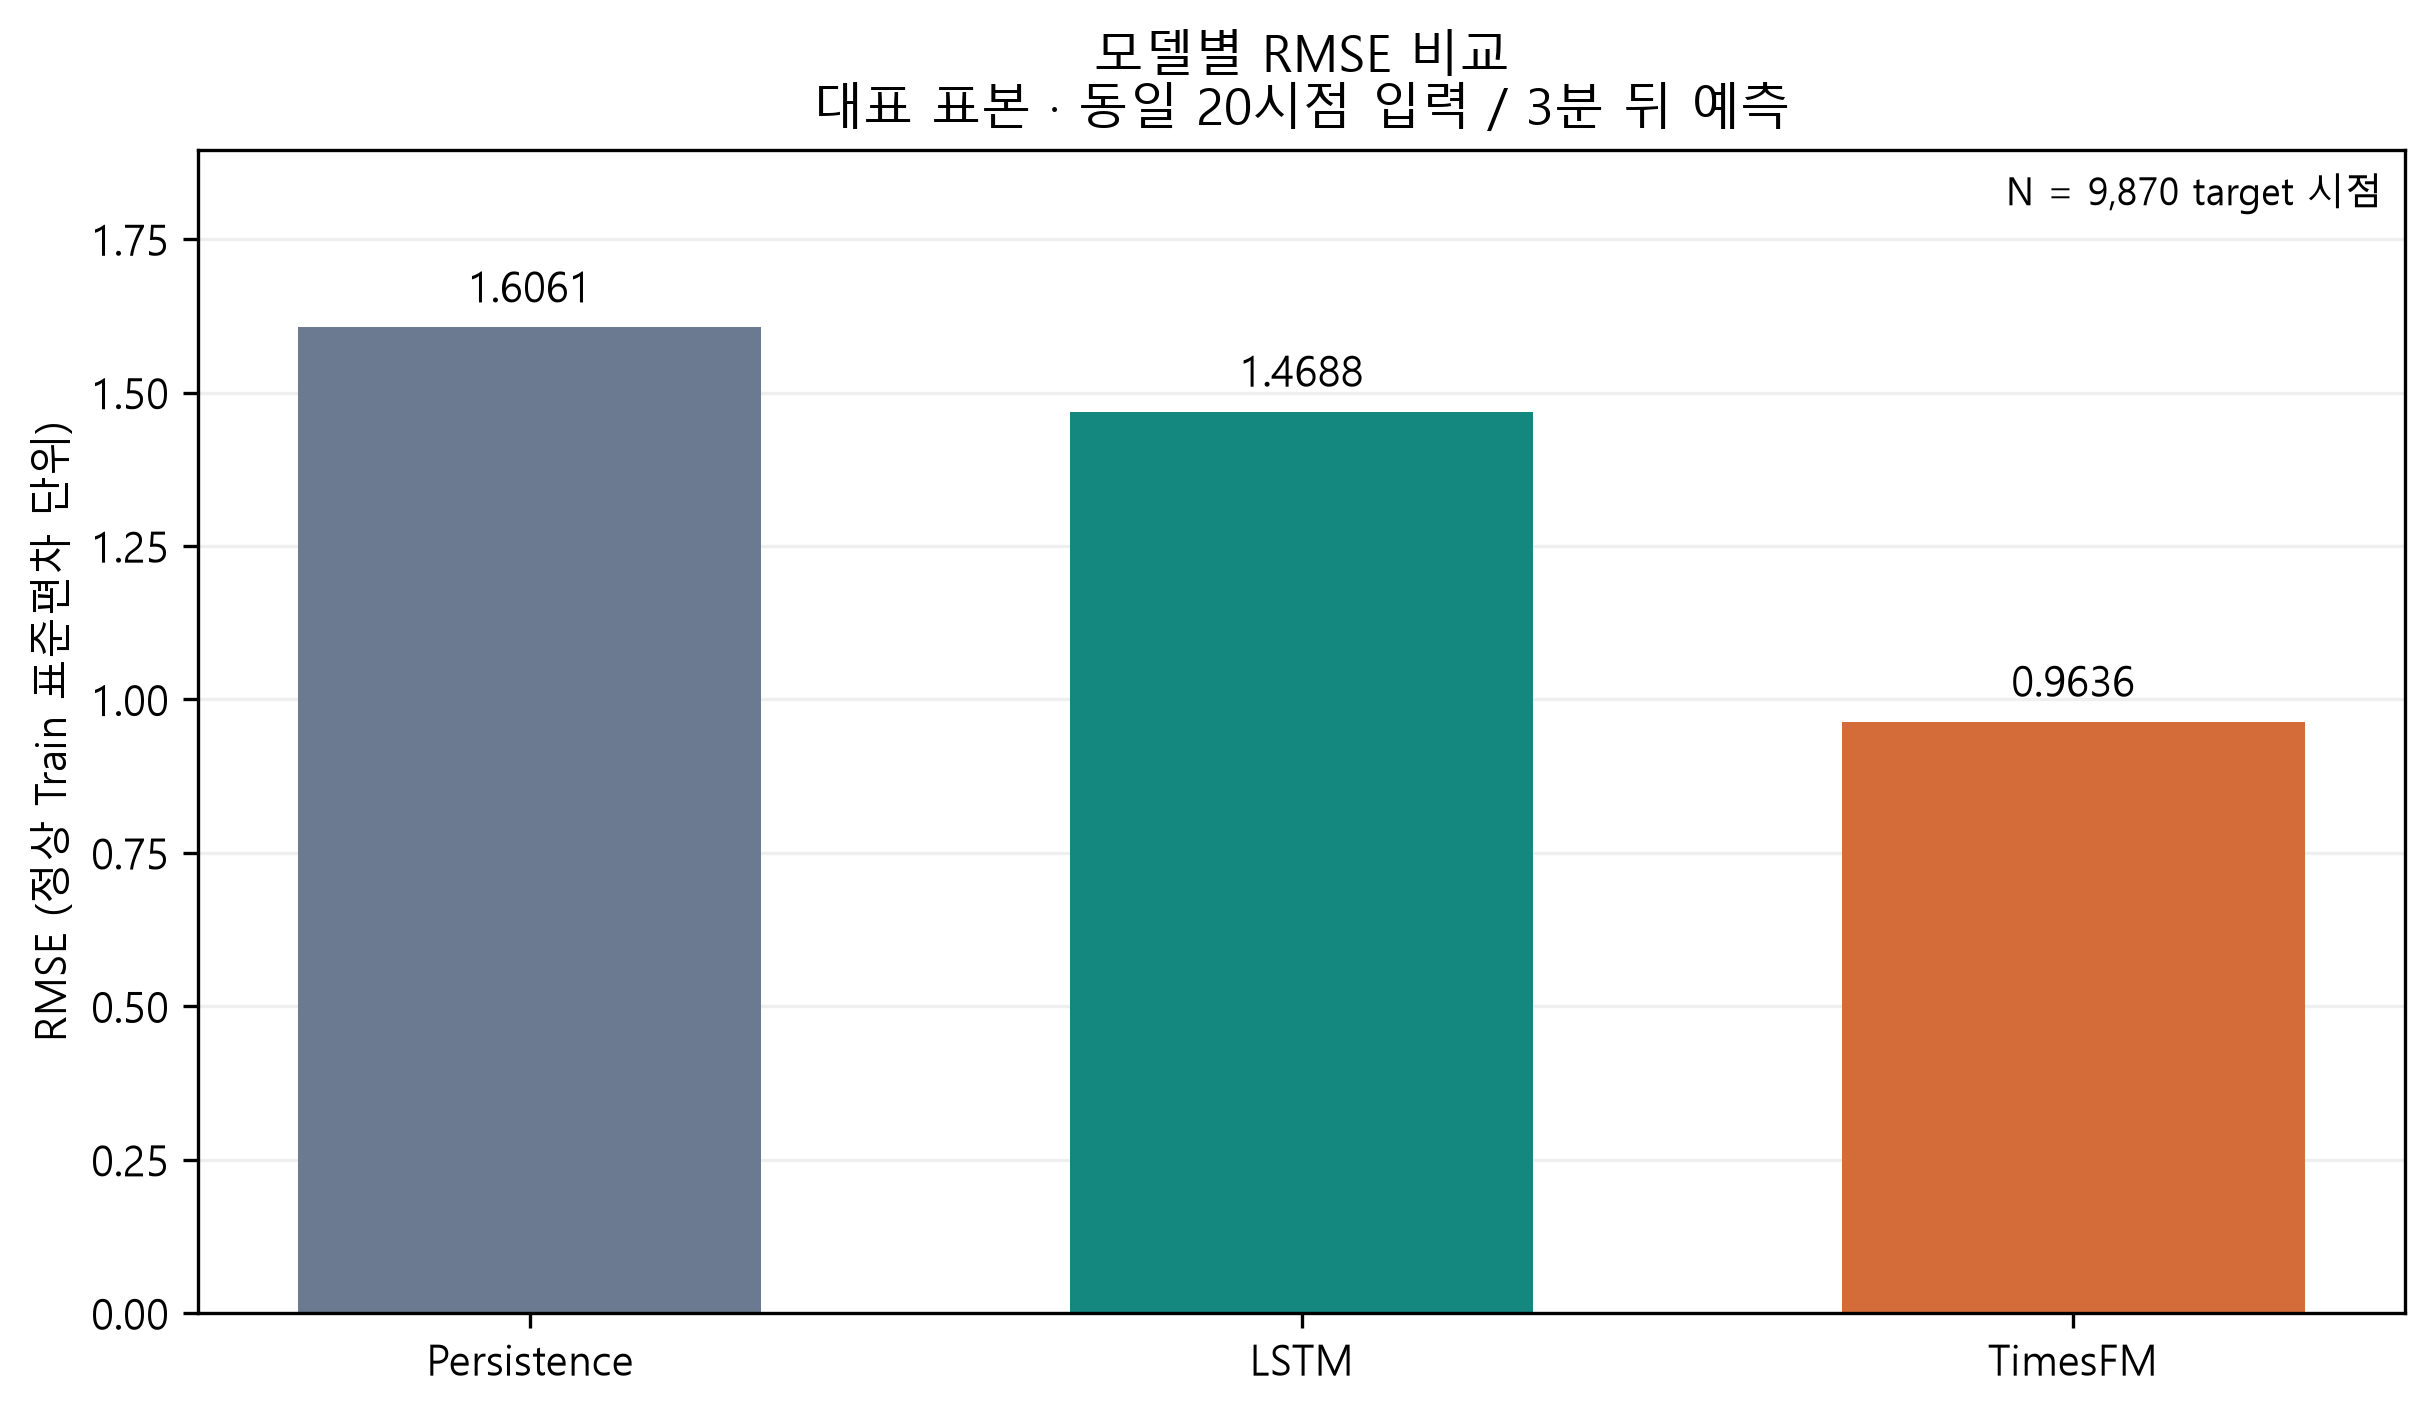

전체 대표 표본의 모델별 RMSE. 세 모델의 target과52변수가 동일하다.

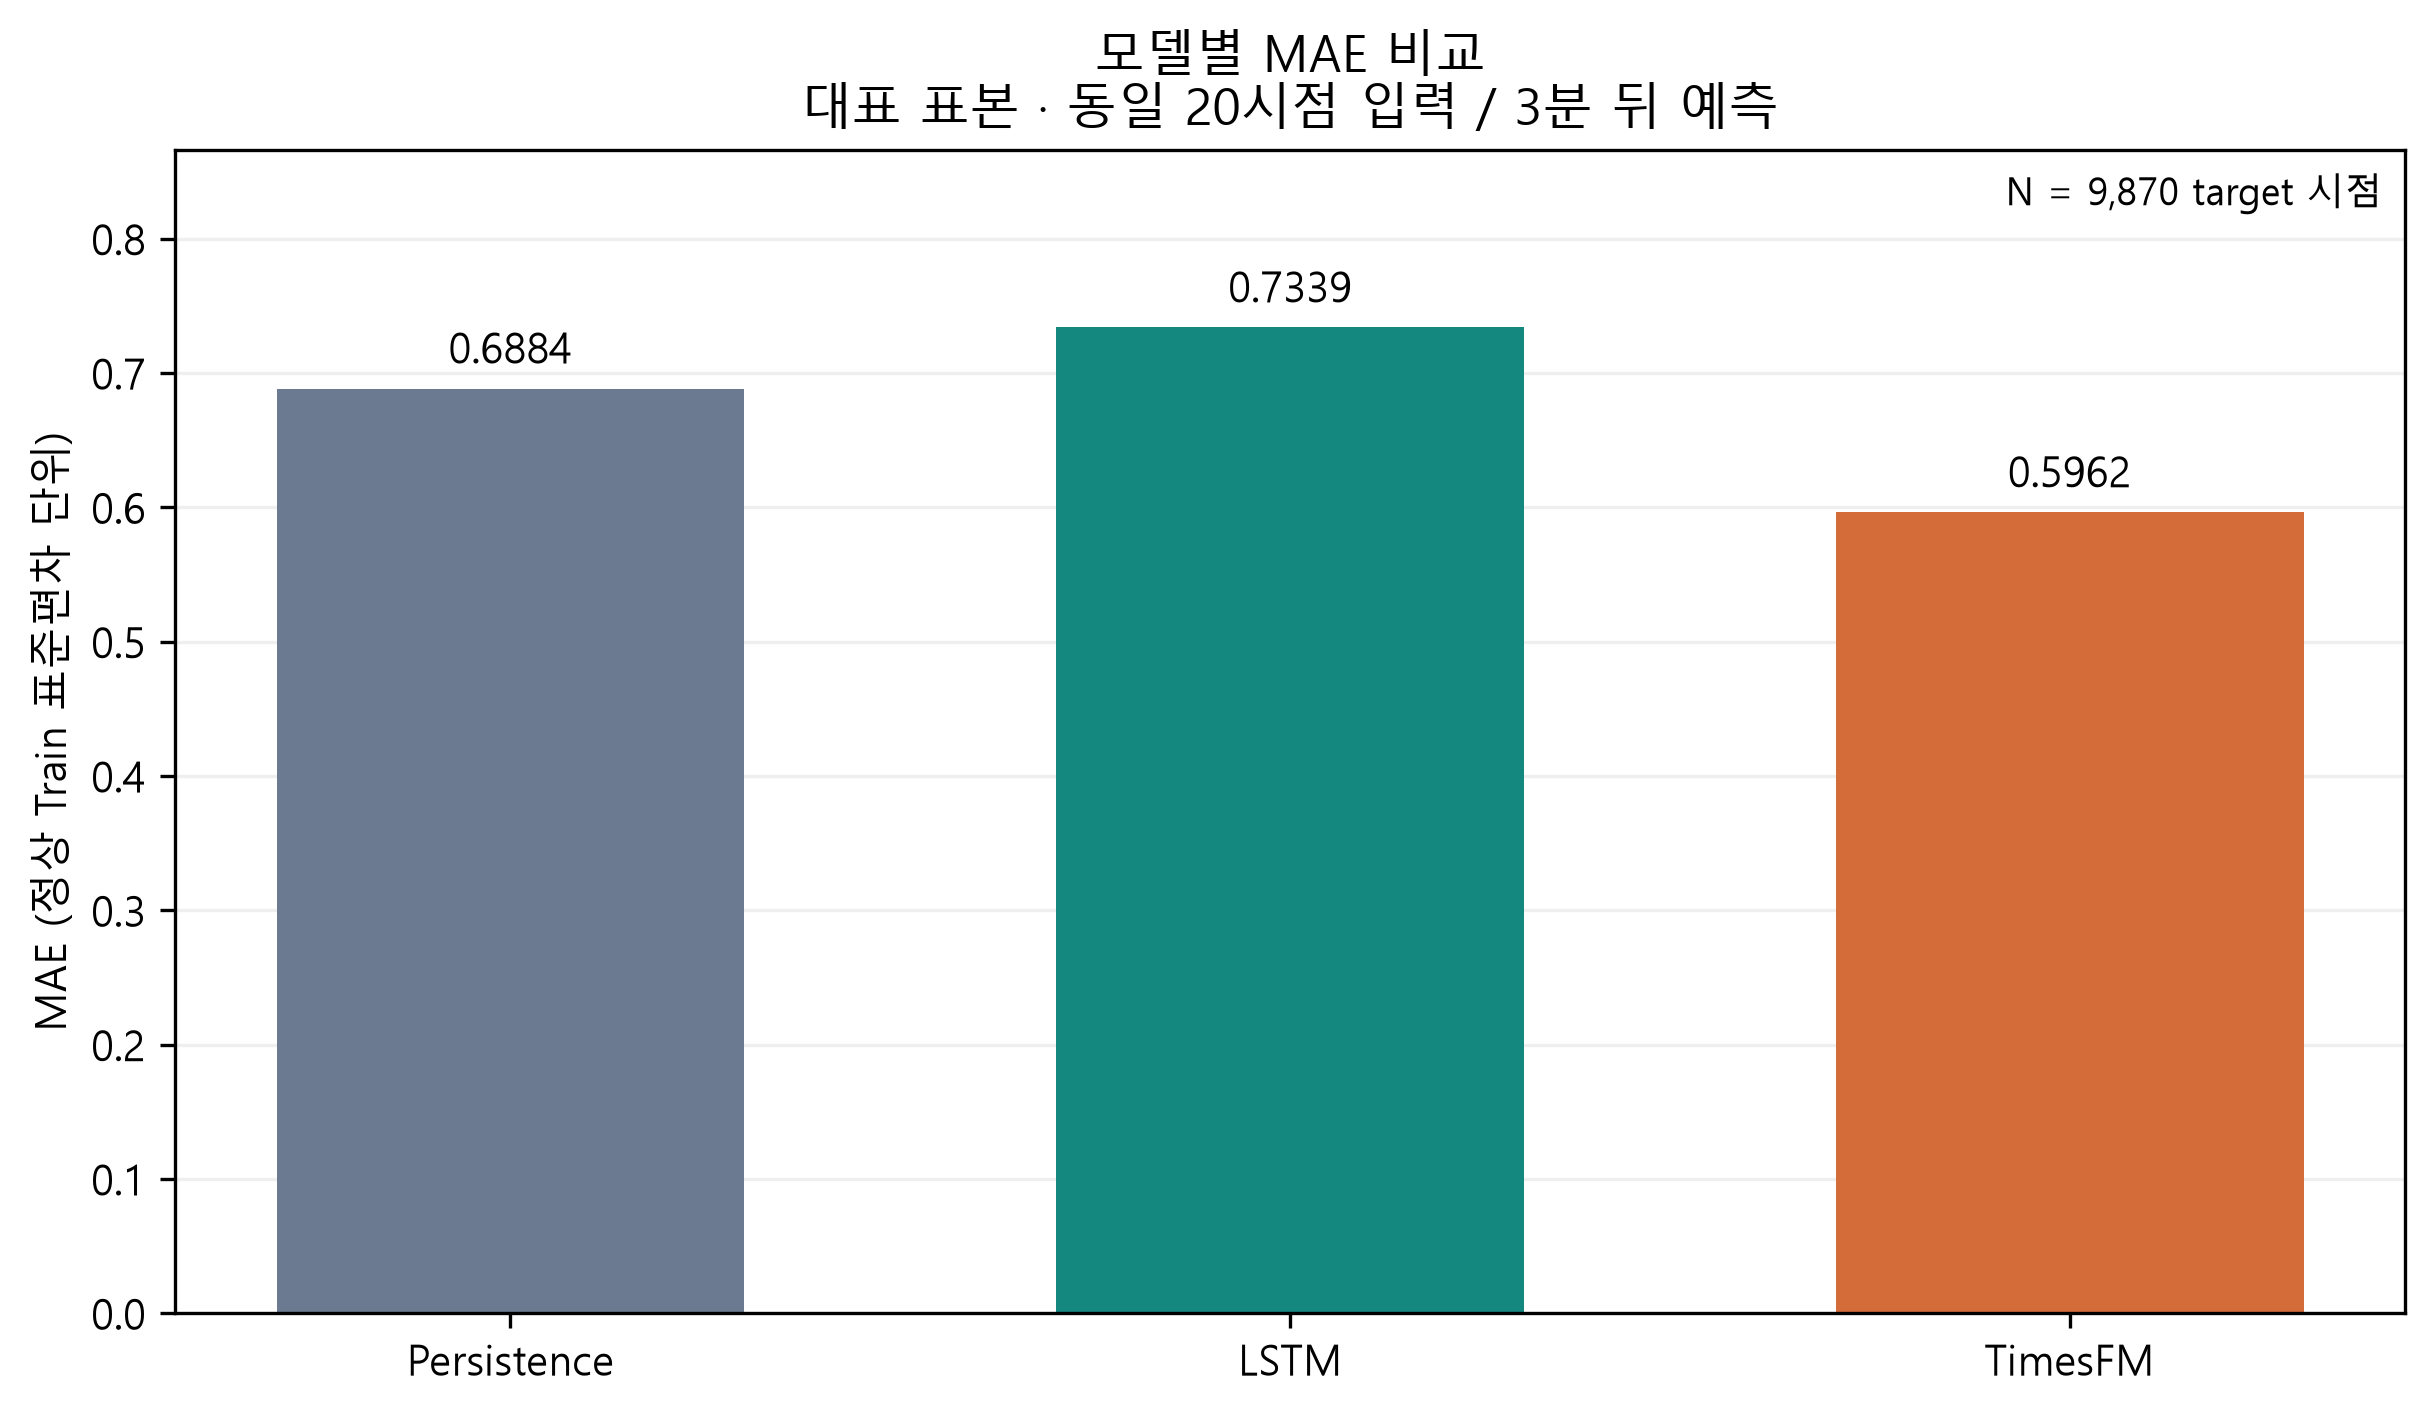

전체 대표 표본의 모델별 MAE. Persistence도 함께 확인해 학습 모델의 실제 이득을 판단한다.

## 9. 정상 구간과 고장 이후를 나누면?

**정상 구간에서는 LSTM이 더 정확하다.** TimesFM의 RMSE/MAE가 각각8.83%/6.99% 높다. **고장 이후에는 TimesFM이 더 정확하다.** RMSE/MAE가 각각37.52%/22.88% 낮다.

고장 이후8,000개가 표본의81.1%이므로 이 구간의 개선이 전체 지표에 크게 반영됐다. 따라서 “TimesFM이 정상과 고장 모두에서 우수하다”는 해석은 맞지 않는다.

In [7]:
segments=metrics.copy()
segments['평가 구간']=segments.cohort.map(COHORTS)
display(segments[['평가 구간','model','target_rows','normalized_rmse','normalized_mae']].rename(columns={'model':'모델','target_rows':'target 수','normalized_rmse':'RMSE (Train SD)','normalized_mae':'MAE (Train SD)'}))
changes=[]
for cohort,label in COHORTS.items():
    a=metrics.query('cohort==@cohort').set_index('model')
    changes.append([label,*[100*(1-a.loc['TimesFM',k]/a.loc['LSTM',k]) for k in ['normalized_rmse','normalized_mae']]])
display(pd.DataFrame(changes,columns=['평가 구간','TimesFM RMSE 감소율 (%)','TimesFM MAE 감소율 (%)']))
display(Markdown('감소율이 음수이면 TimesFM이 LSTM보다 나쁘다는 뜻이다.'))

,평가 구간,모델,target 수,RMSE (Train SD),MAE (Train SD)
0,전체 표본,LSTM,9870,1.468793,0.733885
1,정상 전용 실행,LSTM,470,0.755259,0.531908
2,정상 구간,LSTM,1870,0.757884,0.534474
3,고장 이후,LSTM,8000,1.589771,0.780497
4,전체 표본,Persistence,9870,1.606110,0.688398
5,정상 전용 실행,Persistence,470,1.015090,0.653067
6,정상 구간,Persistence,1870,0.998776,0.635960
7,고장 이후,Persistence,8000,1.717379,0.700655
8,전체 표본,TimesFM,9870,0.963627,0.596248
9,정상 전용 실행,TimesFM,470,0.837035,0.580832


,평가 구간,TimesFM RMSE 감소율 (%),TimesFM MAE 감소율 (%)
0,전체 표본,34.393299,18.754581
1,정상 구간,-8.828163,-6.991579
2,고장 이후,37.520220,22.875741
3,정상 전용 실행,-10.827603,-9.197906


감소율이 음수이면 TimesFM이 LSTM보다 나쁘다는 뜻이다.

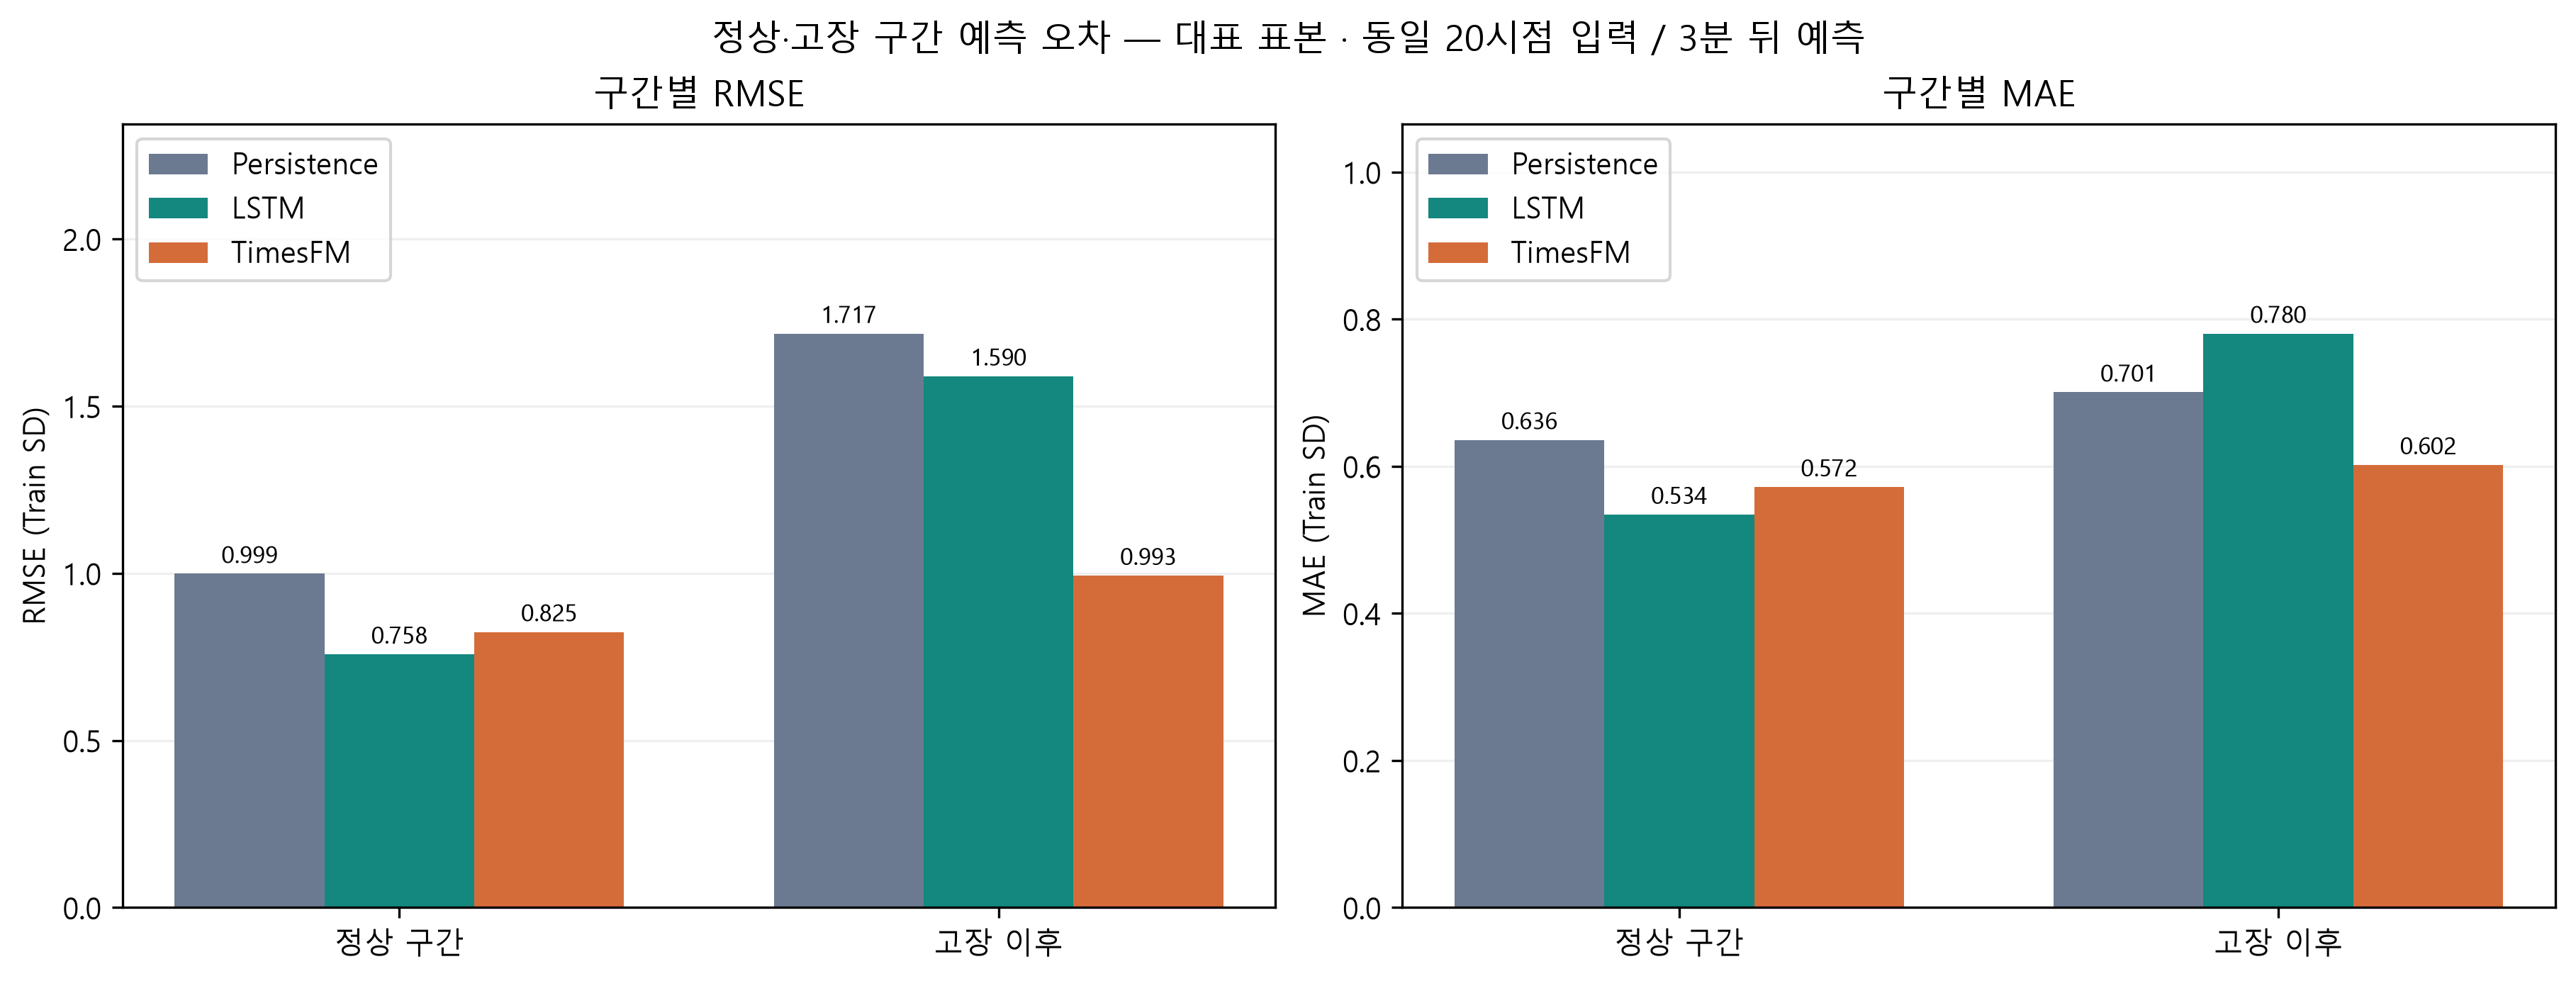

정상 구간에서는 LSTM, 고장 이후에서는 TimesFM이 유리하다. 전체 평균만 읽으면 이 차이가 가려진다.

## 10. 52개 변수별 비교

RMSE와 MAE 각각52개 중42개 변수에서 TimesFM이 LSTM보다 낮은 오차를 보였다. RMSE 개선 변수 집합과 MAE 개선 변수 집합이 완전히 동일하다는 뜻은 아니다. 아래 표는 두 모델의 오차와 감소율을 실제 내장 결과로 계산한다.

In [8]:
names=[f'xmeas_{j}' for j in range(1,42)]+[f'xmv_{j}' for j in range(1,12)]
rmse=variables.pivot(index='variable',columns='model',values='normalized_rmse').loc[names]
mae=variables.pivot(index='variable',columns='model',values='normalized_mae').loc[names]
comparison=pd.DataFrame({'LSTM RMSE':rmse.LSTM,'TimesFM RMSE':rmse.TimesFM,'RMSE 감소율 (%)':100*(1-rmse.TimesFM/rmse.LSTM),'LSTM MAE':mae.LSTM,'TimesFM MAE':mae.TimesFM,'MAE 감소율 (%)':100*(1-mae.TimesFM/mae.LSTM)})
display(comparison.round(5))
display(Markdown(f"TimesFM 개선 변수 수: RMSE **{(rmse.TimesFM<rmse.LSTM).sum()}/52**, MAE **{(mae.TimesFM<mae.LSTM).sum()}/52**."))
assert (rmse.TimesFM<rmse.LSTM).sum()==42
assert (mae.TimesFM<mae.LSTM).sum()==42

,LSTM RMSE,TimesFM RMSE,RMSE 감소율 (%),LSTM MAE,TimesFM MAE,MAE 감소율 (%)
variable,,,,,,
xmeas_1,0.78044,0.75268,3.55766,0.53347,0.50744,4.87794
xmeas_2,0.89375,0.95230,-6.55056,0.68839,0.72197,-4.87757
xmeas_3,0.86580,0.92996,-7.40991,0.67817,0.71731,-5.77111
xmeas_4,1.19108,0.98775,17.07133,0.91933,0.75935,17.40202
xmeas_5,1.27330,1.15199,9.52722,0.99165,0.86812,12.45759
xmeas_6,1.22719,1.06647,13.09651,0.97735,0.82851,15.22915
xmeas_7,0.45738,0.34466,24.64432,0.29844,0.23486,21.30500
xmeas_8,1.12382,1.02799,8.52671,0.87879,0.79253,9.81563
xmeas_9,4.63822,1.89553,59.13238,1.80981,1.08382,40.11427


TimesFM 개선 변수 수: RMSE **42/52**, MAE **42/52**.

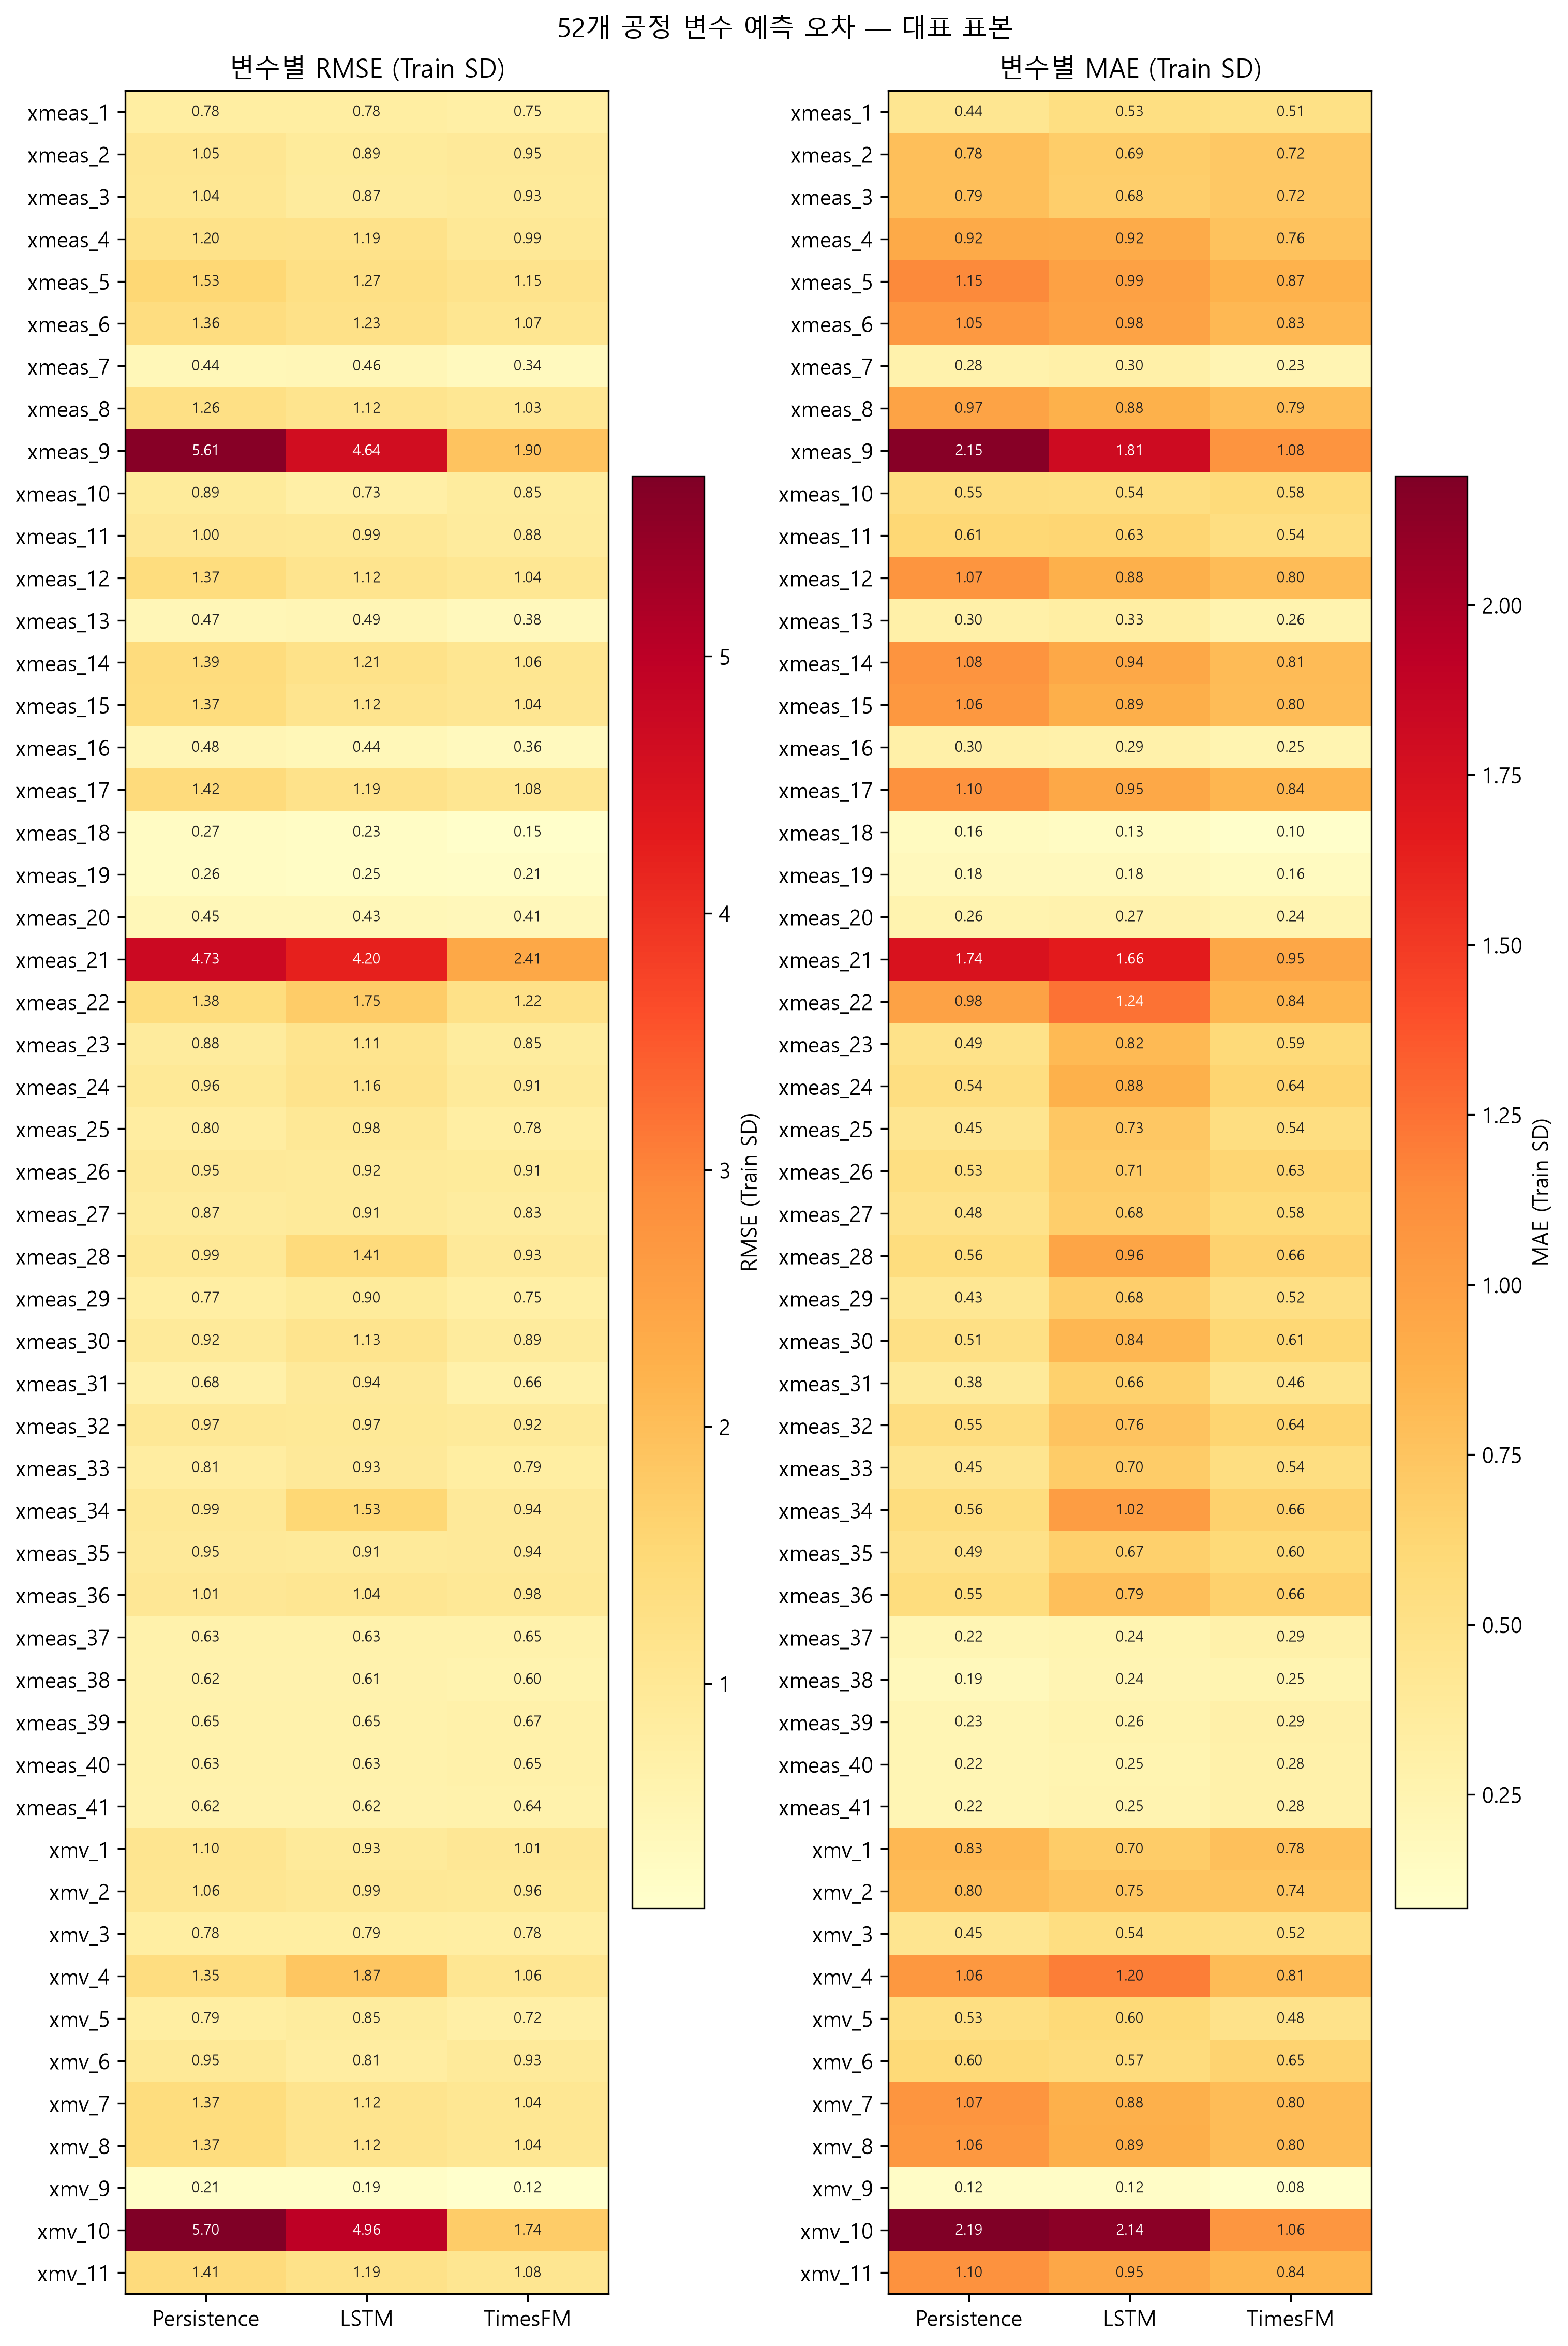

52개 변수의 정규화 RMSE/MAE. 두 패널의 색 눈금은 별도이며 모든 값의 단위는 Train SD다.

큰 RMSE 감소는 XMV10, XMEAS9, XMEAS21 등에서 관측됐다. 반대로 XMV6, XMEAS10, XMV1 등은 LSTM이 더 낮은 RMSE를 보였다. 전체 지표의 개선과 개별 변수의 개선을 구분해야 한다.

## 11. 고장 시나리오별 추가 확인

다음 표는 이미 저장된105개 시계열의 예측에서 고장 시나리오별 오차를 재집계한 것이다. 재학습·새 추론을 수행한 결과가 아니다. 각 시나리오의 고장 전·후 전체 표본470개 target을 포함한다. 0번은 정상 전용 시나리오다.

In [9]:
grouped=trajectory_errors.groupby(['fault','model'])[['target_rows','sse','sae']].sum().reset_index()
grouped['rmse']=np.sqrt(grouped.sse/(grouped.target_rows*52))
grouped['mae']=grouped.sae/(grouped.target_rows*52)
f_rmse=grouped.pivot(index='fault',columns='model',values='rmse')
f_mae=grouped.pivot(index='fault',columns='model',values='mae')
fault_comparison=pd.DataFrame({'LSTM RMSE':f_rmse.LSTM,'TimesFM RMSE':f_rmse.TimesFM,'RMSE 감소율 (%)':100*(1-f_rmse.TimesFM/f_rmse.LSTM),'LSTM MAE':f_mae.LSTM,'TimesFM MAE':f_mae.TimesFM,'MAE 감소율 (%)':100*(1-f_mae.TimesFM/f_mae.LSTM)})
fault_comparison.index.name='faultNumber (0=정상)'
display(fault_comparison.round(5))
# 시나리오 집계를 다시 합쳐도 기존 전체 표본 지표와 일치해야 한다.
for model in MODELS:
    a=grouped[grouped.model==model]
    np.testing.assert_allclose([np.sqrt(a.sse.sum()/(a.target_rows.sum()*52)),a.sae.sum()/(a.target_rows.sum()*52)],overall.loc[model,['normalized_rmse','normalized_mae']].to_numpy(dtype=float),rtol=2e-9,atol=2e-9)
print('시나리오별 재집계와 전체 지표 일치: PASS')

,LSTM RMSE,TimesFM RMSE,RMSE 감소율 (%),LSTM MAE,TimesFM MAE,MAE 감소율 (%)
faultNumber (0=정상),,,,,,
0,0.75526,0.83703,-10.82760,0.53191,0.58083,-9.19791
1,1.24958,0.85996,31.18019,0.90770,0.60082,33.80904
2,1.42006,0.83468,41.22267,0.91361,0.57876,36.65155
3,0.76601,0.82259,-7.38707,0.53676,0.56716,-5.66489
4,1.06375,0.84599,20.47063,0.65070,0.58440,10.18987
5,0.80352,0.83680,-4.14177,0.56519,0.58096,-2.79090
6,1.20224,0.67550,43.81275,0.84251,0.34287,59.30349
7,1.25561,0.86965,30.73837,0.71796,0.60263,16.06373
8,1.07047,0.93517,12.63990,0.76651,0.65767,14.19965


시나리오별 재집계와 전체 지표 일치: PASS


## 12. 실제값과 예측값, 고장 주입 시점

예시는 사전에 고정한 simulationRun50의 Fault1, 변수 XMEAS1·7·9·21이다. 오차가 좋은 사례만 사후 선택한 것이 아니다. 세 모델은 모두 한 시점 앞(3분 뒤)을 예측한다.

점선480분은 고장 주입 경계이며 고장 이후 첫 관측은 sample161(483분)이다. 시간은 sample×3분으로 표시했다. **그림은 선택된 평가 시점만 선으로 연결하며, 생략된 중간 시점을 추론했다는 뜻은 아니다.**

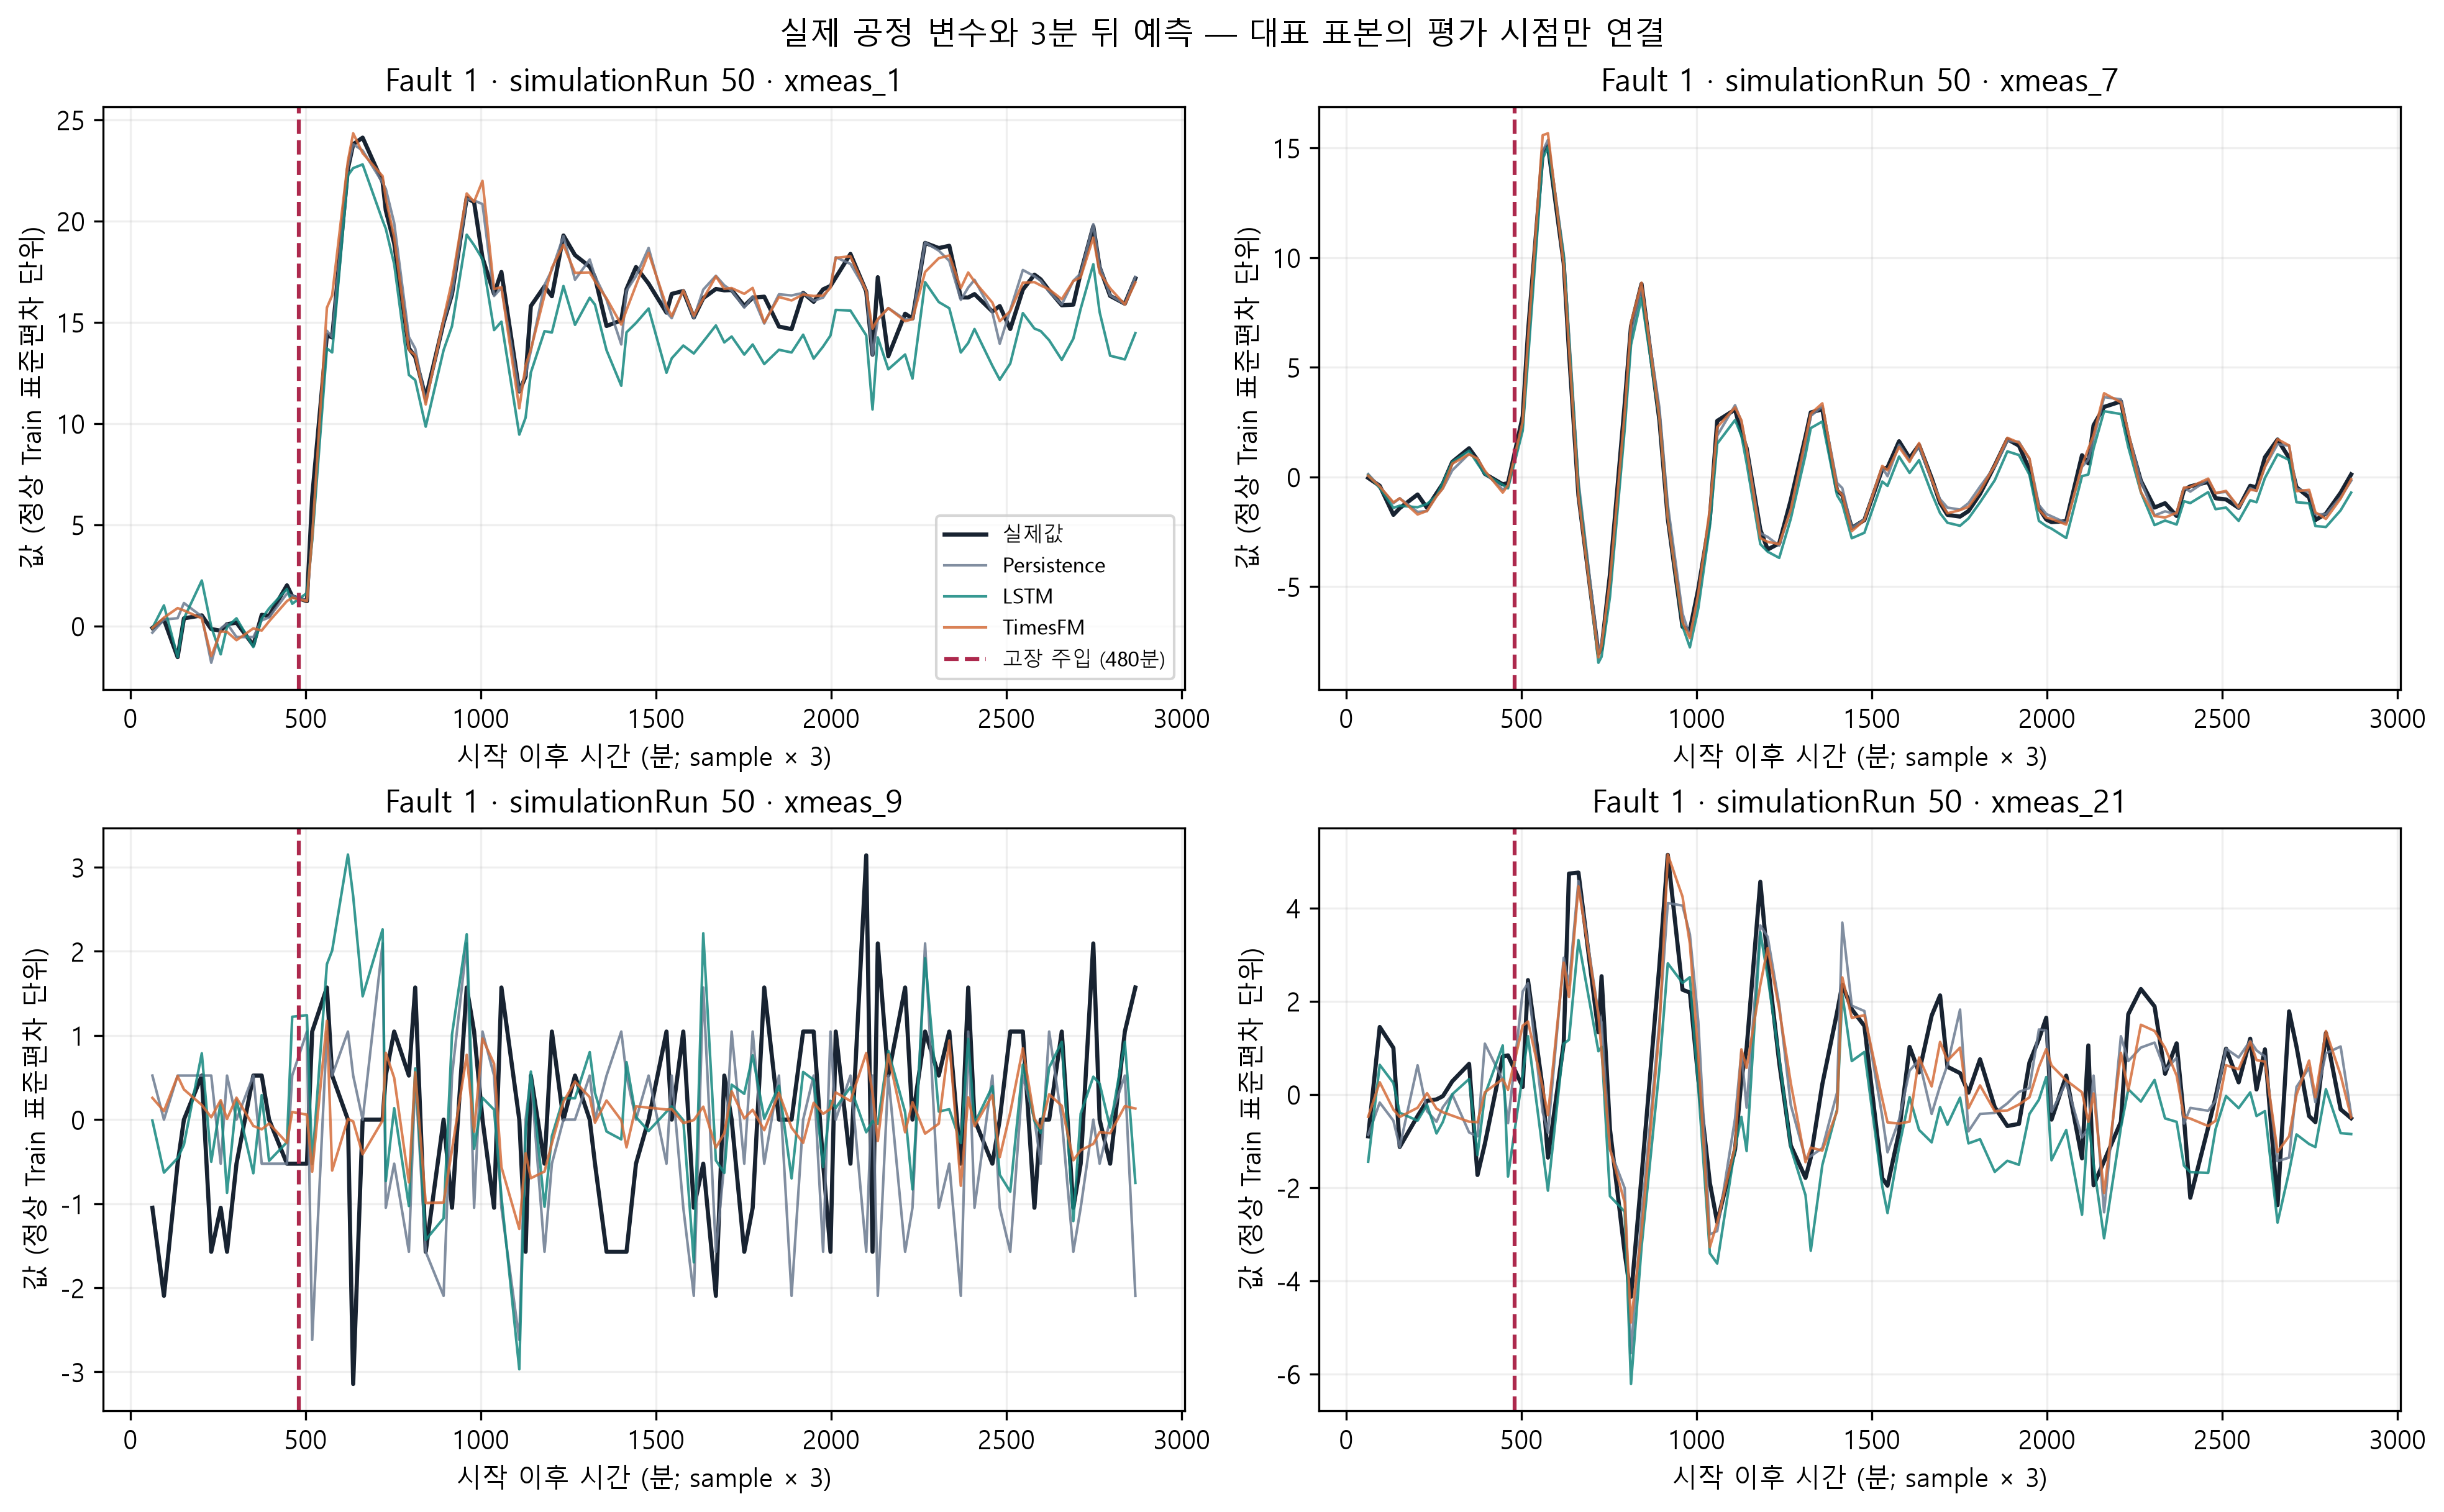

실제 공정 변수값과 Persistence/LSTM/TimesFM 예측. y축은 Train SD로 표준화한 값이다.

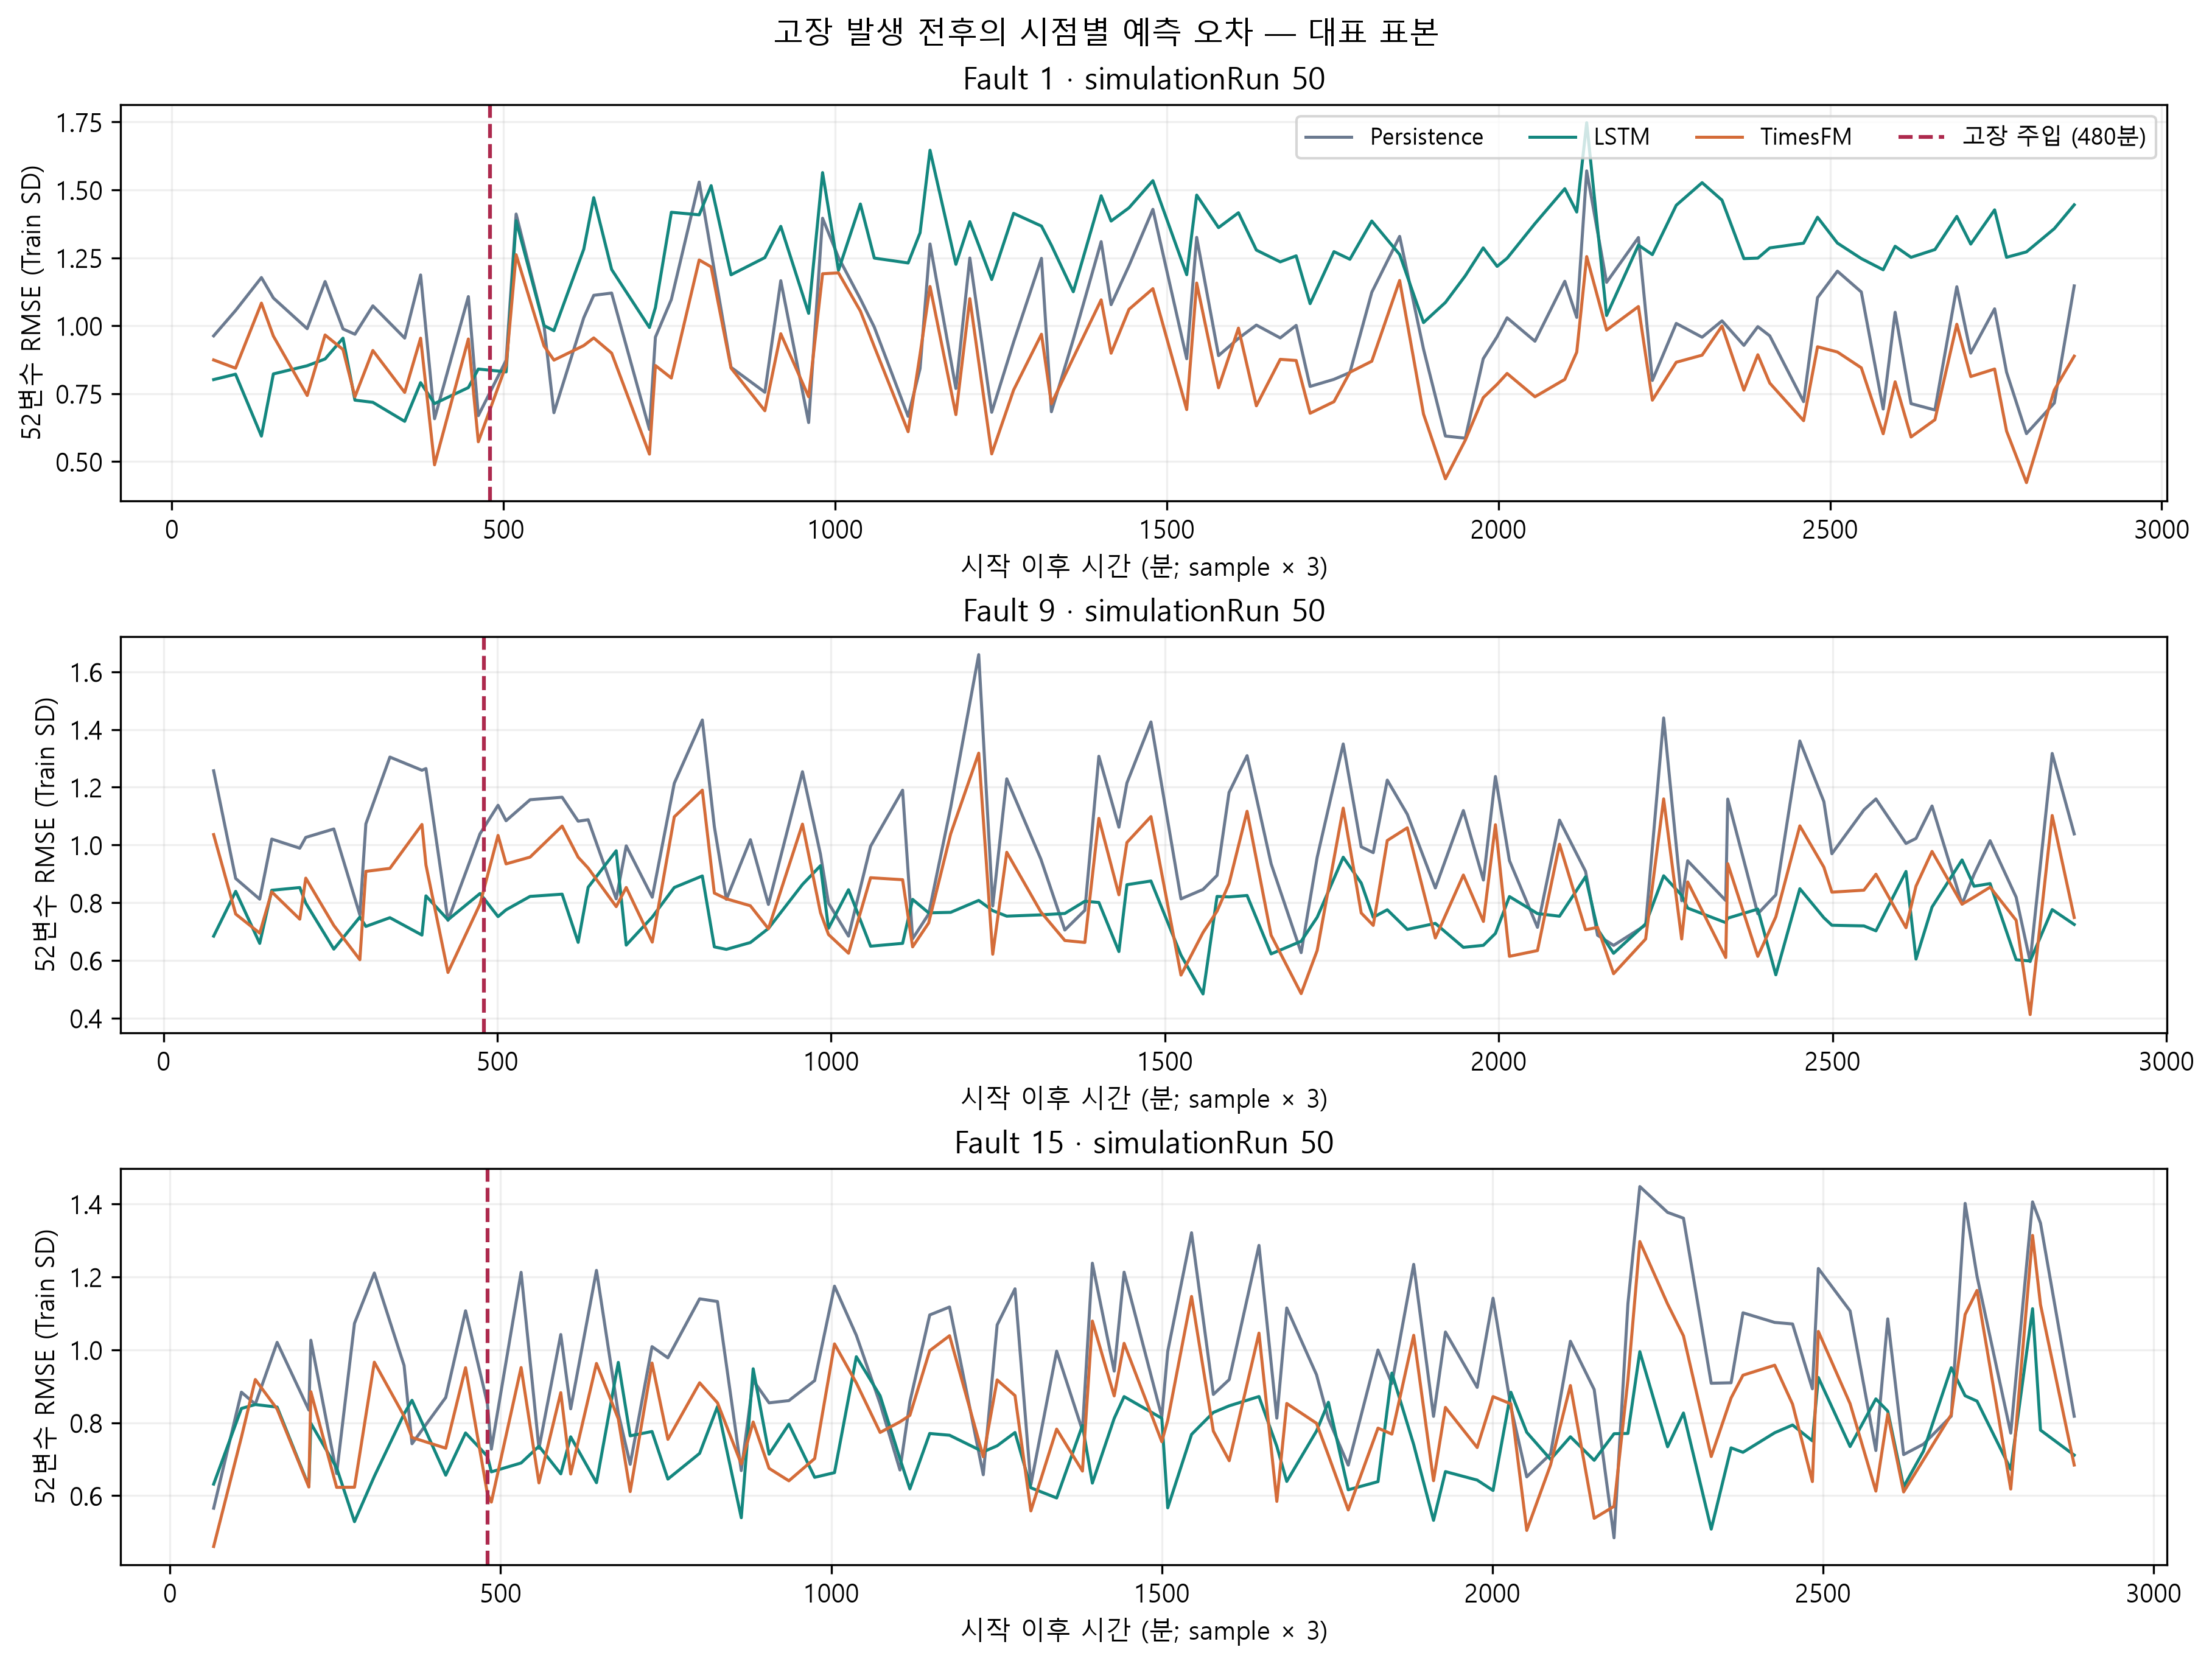

Fault1·9·15에서52변수의 시점별 RMSE. 고장 경계 전후의 오차 변화를 비교한다.

## 13. 설치·실행 환경과 Windows 문제 해결

기존 환경의 NumPy·PyTorch 버전을 변경하지 않고 별도 `.venv`를 만들었다. 최초 pip 설치의 WinError10013은 네트워크 제한이 원인이었고 허용된 다운로드 경로로 해결했다. GPU 드라이버와 호환되는 CUDA12.1 PyTorch wheel을 사용했다.

출력 인코딩은 UTF-8로 설정했다. Jupyter의 사용자 프로필 history 읽기 전용 문제는 IPYTHONDIR·runtime 경로를 실험 폴더 안으로 지정해 해결했다. CUDA/cuDNN 배치 크기에 따른 작은 LSTM 수치 차이를 피하기 위해 저장 예측 재현 검사는 동일한94창 배치에서 수행했다. FP32가 본 비교이며 BF16은 처리속도 탐색에만 사용했다.

In [10]:
env=SNAPSHOT['environment']
display(pd.DataFrame(list(env['packages'].items()),columns=['패키지','실제 사용 버전']))
display(Markdown(f"GPU: **{env['device']}** · CUDA {env['torch_cuda']} · cuDNN TF32 허용={env['cudnn_allow_tf32']} · matmul TF32 허용={env['matmul_allow_tf32']}"))

,패키지,실제 사용 버전
0,timesfm,3.0.2
1,torch,2.5.1+cu121
2,numpy,2.5.4
3,pandas,3.1.1
4,scikit-learn,1.9.1
5,joblib,1.6.0
6,matplotlib,3.11.2
7,huggingface_hub,2.4.0
8,safetensors,0.8.0
9,nbformat,5.11.1


GPU: **NVIDIA GeForce RTX 3060 Laptop GPU** · CUDA 12.1 · cuDNN TF32 허용=True · matmul TF32 허용=False

## 14. 누출·지표·보존 검증

입력 창은 한 시계열 안에서 생성하며 미래 target을 포함하지 않는다. 정상 Train의 scaler 통계를 재계산해 기존 artifact와 일치함을 확인했다. 공식 Test를 scaler fit이나 추가 학습에 쓰지 않았다. TimesFM의 사전학습 corpus에 TEP가 포함됐는지까지 확인한 것은 아니므로 pretrained 데이터 중복 가능성을 배제했다는 주장은 하지 않는다.

In [11]:
checks=SNAPSHOT['checks']
assert all(checks[k]['passed'] for k in checks)
assert checks['preservation_check.json']['changed']==[]
validation=pd.DataFrame([
 ['Train 전용 scaler 재계산 일치',checks['pilot_fp32_validation.json']['scaler_train_only_verified']],
 ['Train/Validation family 분리',checks['pilot_fp32_validation.json']['train_validation_family_disjoint']],
 ['미래값 변경이 과거 입력·예측에 영향 없음',checks['pilot_fp32_validation.json']['future_perturbation_checked']],
 ['TimesFM 배치 독립성',checks['pilot_fp32_validation.json']['batch_independence_checked']],
 ['정답·Persistence가 공식 Test 캐시와 일치',checks['result_validation.json']['actual_and_persistence_match_official_Test_cache']],
 ['저장 예측으로 전체·변수별 지표 재계산',checks['result_validation.json']['summary_and_variable_metrics_recomputed_from_predictions']],
 ['기존 보호 파일409개 변경 없음',checks['preservation_check.json']['passed']],
],columns=['실제로 수행한 검증','통과'])
display(validation)
display(Markdown('본 종합 노트북은 내장 스냅샷의 지표 산술·표본 수·시나리오 재집계를 검증한다. 위의 원 데이터·모델 검사는 이전 실제 실험에서 저장된 통과 기록이다.'))

,실제로 수행한 검증,통과
0,Train 전용 scaler 재계산 일치,True
1,Train/Validation family 분리,True
2,미래값 변경이 과거 입력·예측에 영향 없음,True
3,TimesFM 배치 독립성,True
4,정답·Persistence가 공식 Test 캐시와 일치,True
5,저장 예측으로 전체·변수별 지표 재계산,True
6,기존 보호 파일409개 변경 없음,True


본 종합 노트북은 내장 스냅샷의 지표 산술·표본 수·시나리오 재집계를 검증한다. 위의 원 데이터·모델 검사는 이전 실제 실험에서 저장된 통과 기록이다.

## 15. 결과를 어떻게 해석해야 하나?

1. **표본 전체에서는 TimesFM이 더 정확했다.** RMSE34.39%, MAE18.75% 감소했다.
2. **정상 운전은 LSTM이 유리했다.** 정상 데이터만 학습한 LSTM이 정상 구간에서 강점을 보였다.
3. **고장 이후는 TimesFM이 유리했다.** LSTM의 정상 학습 범위를 벗어난 조건에서 TimesFM의 낮은 오차가 관측됐다. 이것이 반드시 모델 구조만의 효과라는 인과 결론은 아니다.
4. **20시점·1시점 예측이라는 조건의 결과다.** 더 긴 문맥·다른 예측 길이·fine-tuning 결과로 일반화하지 않는다.
5. **표본의 우열과 전체 Test의 우열은 다르다.** 기존 전체 LSTM RMSE1.494316과 이번 표본 TimesFM RMSE0.963627을 직접 비교하면 평가 분모가 달라 잘못이다.
6. **공정 변수 회귀와 고장 유형 분류를 구분한다.** 본 RMSE/MAE는 CNN의 Accuracy 향상을 뜻하지 않는다.

학술 보고에서는 “정상·고장 시나리오 전체를 포함하는5개 Test family의 대표 표본에서 TimesFM Zero-shot의 통합 예측 오차가 낮았고, 개선은 주로 고장 이후 구간에서 관측되었다”라고 기술하는 것이 현재 증거에 맞다.

## 16. 결과 위치와 재현 방법

| 파일 | 용도 |
|---|---|
| `timesfm_experiment/experiment_summary.md` | 상세 한국어 보고서 |
| `timesfm_experiment/TimesFM_TEP_실험.ipynb` | 실제 GPU 재추론·저장 예측 검증이 포함된 실행 노트북 |
| `timesfm_experiment/model_comparison.csv` | 같은 표본의 세 모델 전체·구간별 지표 |
| `timesfm_experiment/variable_metrics.csv` | 변수별 정규화·원 스케일 지표 |
| `timesfm_experiment/predictions/` | 모든 표본의 실제값과 세 모델 예측 |
| `timesfm_experiment/figures/` | 논문·PPT용300dpi PNG6종 |
| `timesfm_experiment/requirements.txt` | 독립 환경 고정 버전 |
| `timesfm_experiment/README.md` | 실행·재개·전체 평가 안내 |

프로젝트 루트에서 PowerShell로 실행할 때:

```powershell
# 대표 표본 실험 재개/결과 생성 (기존 checkpoint 사용)
.\timesfm_experiment\run_experiment.ps1

# 별도 full_evaluation 폴더에서 전체 평가 (현재 미실행, 수일 소요 가능)
.\timesfm_experiment\run_experiment.ps1 -Full

# 이 종합 노트북만 다시 생성하고 실행
.\timesfm_experiment\.venv\Scripts\python.exe .\timesfm_experiment\build_comparison_notebook.py
```

## 17. 공식 출처와 실험 자료의 식별

- [Google Research TimesFM 공식 저장소](https://github.com/google-research/timesfm)
- [공식 모델 카드·가중치](https://huggingface.co/google/timesfm-3.0-pytorch)
- [공식 다변량 Evaluator](https://github.com/google-research/timesfm/blob/master/src/timesfm3/torch/evaluator.py)

이 노트북의 버전 설명은 이번에 설치·실행한 버전 기록이다. TimesFM3.0 가중치에는 비상업·비생산 라이선스가 적용되며 소스 Apache-2.0와 별도다. 실험 시 확인한 문서 원문과 모델 revision은 `timesfm_experiment/sources/`와 `checkpoint/`에 보존했다.

In [12]:
display(pd.DataFrame(list(SNAPSHOT['source_sha256'].items()),columns=['이번 노트북의 원 결과 파일','SHA-256']))
print('정리 완료: 대표 표본의 실제 결과 / 전체 Test TimesFM 미실행 / 기존 모델 보존')

,이번 노트북의 원 결과 파일,SHA-256
0,model_comparison.csv,b03457a52d9369f84c613edcf1000e0a91aa73f76a39fe...
1,variable_metrics.csv,87783da1e4da6d5cfa8a08495875fa2af416f5d1939d17...
2,sampling_manifest.json,5276f167a6ca69059ebcc021cf7dd04b29c3a2e5a487ad...
3,environment.json,7b1190effb9adc25abb8536fd82ebe26fb638ea28b302a...
4,pilot_fp32_validation.json,1c24f5234d9cfa81016bcac9dfc62b717c0615c9063890...
5,throughput_benchmark.csv,b2ecc8138831dd162b830771bc118ab403df00a38350be...
6,result_validation.json,f41f0af3706ecc0b43bf7a1fbcfef9c94a328f2e44c6c3...
7,preservation_check.json,68caeee577ad297ff7a955d4cd0c2e88c4c1391fb9e080...
8,progress.json,d973bb4cbff169a987f764c91dd5dba4fb9910557c2071...


정리 완료: 대표 표본의 실제 결과 / 전체 Test TimesFM 미실행 / 기존 모델 보존
